# Local Region Image Editing: interface

**Module:** Intelligent Interactive Systems
**Assignment:** Assignment 2, project report and prototype
**Name:** Leeya Hundal
**Student number:** 3183349
**Email:** LXH1038@student.bham.ac.uk
**Repository:** https://github.com/Leeya01/Assignment-A2-Project
**Submission release:** a2-submission
**Last updated:** 15/11/26

This notebook builds the interface for a local region image editor. The user paints over part of an image, types a short instruction and only that area is changed. It also covers the before and after view, the mask check, variants, edit history and the settings log. Notebook 1 (`01-inpainting.ipynb`) holds the earlier inpainting experiments.

**To run it:** set the accelerator to GPU T4, turn Internet on, then run the cells from top to bottom. The final app cell goes last and prints a `gradio.live` link.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/leeyahundal/testimage/testImage.png


# 01 Inpainting test

Loading the inpainting model and checking the GPU works. Next step is running one edit on a test image.

In [20]:
# switch off the safety checker (it blacked out two harmless images)
pipe.safety_checker = None

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter
from simple_lama_inpainting import SimpleLama

lama = SimpleLama()

Downloading: "https://github.com/enesmsahin/simple-lama-inpainting/releases/download/v0.1.0/big-lama.pt" to /root/.cache/torch/hub/checkpoints/big-lama.pt
100%|██████████| 196M/196M [00:01<00:00, 196MB/s] 


In [3]:
import torch
from diffusers import AutoPipelineForInpainting

# use the GPU if there is one, otherwise fall back to the CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
print("Using device:", device)
if device == "cuda":
    print("GPU name:", torch.cuda.get_device_name(0))

model_id = "stable-diffusion-v1-5/stable-diffusion-inpainting"

pipe = AutoPipelineForInpainting.from_pretrained(model_id, dtype=dtype)
pipe = pipe.to(device)
print("Model loaded")

Using device: cuda
GPU name: Tesla T4


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Model loaded


In [4]:
# list the files in the input folder to find your image path
import os
for folder, subfolders, files in os.walk("/kaggle/input/datasets/leeyahundal/testimage/testImage.png"):
    for f in files:
        print(os.path.join(folder, f))

## First edit

Loading the test image, making a hand-drawn rectangle mask over the flaw, and running one inpainting edit. White in the mask means change this area, black means keep it.

  0%|          | 0/30 [00:00<?, ?it/s]

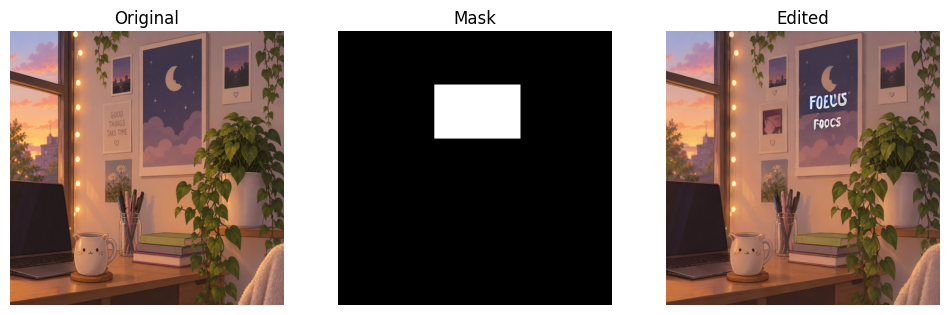

In [6]:
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

# paste the path from the cell above
image_path = "/kaggle/input/datasets/leeyahundal/testimage/testImage.png"

# the model works at 512 by 512
image = Image.open(image_path).convert("RGB").resize((512, 512))

# white means edit this area, black means keep it
mask = Image.new("L", (512, 512), 0)
draw = ImageDraw.Draw(mask)
draw.rectangle([180, 100, 340, 200], fill=255)  # left, top, right, bottom

# describe only the change for the masked area
prompt = "a poster with the word FOCUS"

# fixed seed so the result can be repeated
generator = torch.Generator(device).manual_seed(42)

result = pipe(
    prompt=prompt,
    image=image,
    mask_image=mask,
    num_inference_steps=30,
    generator=generator,
).images[0]

result.save("edited_raw.png")

# show original, mask and result side by side
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, title in zip(axes, [image, mask, result], ["Original", "Mask", "Edited"]):
    ax.imshow(img, cmap="gray" if title == "Mask" else None)
    ax.set_title(title)
    ax.axis("off")
plt.show()

## Paste back and precision check

The model re-draws the whole image internally, so pixels outside the mask can shift slightly. Here the edited area is pasted back onto the original with a softened edge, then the change outside the edit area is measured for the raw output and the pasted-back version.

## Paste back and precision check

The model re-draws the whole image internally, so pixels outside the mask can shift slightly. Here the edited area is pasted back onto the original with a softened edge, then the change outside the edit area is measured for the raw output and the pasted-back version.

Pixels outside the edit area: 240363
Average change outside, raw model output: 6.086
Average change outside, after paste back: 0.0


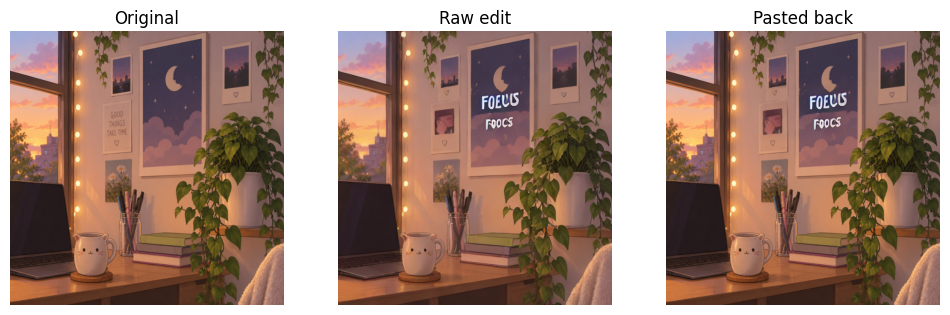

In [7]:
import numpy as np
from PIL import ImageFilter

# soften the mask edge so the edit blends in
soft_mask = mask.filter(ImageFilter.GaussianBlur(4))

# paste the edited area back onto the original image
final = Image.composite(result, image, soft_mask)
final.save("edited_final.png")

# pixels completely outside the edit area
outside = np.array(soft_mask) == 0

# average change per pixel, outside the edit area
orig_arr = np.array(image).astype(float)
raw_diff = np.abs(np.array(result).astype(float) - orig_arr).mean(axis=2)
final_diff = np.abs(np.array(final).astype(float) - orig_arr).mean(axis=2)

print("Pixels outside the edit area:", int(outside.sum()))
print("Average change outside, raw model output:", round(raw_diff[outside].mean(), 3))
print("Average change outside, after paste back:", round(final_diff[outside].mean(), 3))

# show original, raw result and pasted-back result
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, title in zip(axes, [image, result, final], ["Original", "Raw edit", "Pasted back"]):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
plt.show()

## What this section shows

### What I did
- Loaded a Stable Diffusion inpainting model on a Kaggle T4 GPU
- Used one test image (a study space) and a hand-drawn rectangle mask over the poster
- Prompted the model to write the word FOCUS in the masked area
- Pasted the edited area back onto the original with a softened mask edge
- Measured the average pixel change outside the edit area, before and after the paste back

### Results
- Pixels outside the edit area: 240363
- Average change outside, raw model output: 6.086 (on a 0 to 255 scale, roughly 2.4%)
- Average change outside, after paste back: 0.0

### What I noticed
- The model repeated the word and misspelled both copies (FOEUS and FOOCS), so text edits are unreliable with this model
- The raw output also changed areas I did not select, such as the small frame on the left wall and the pen pot, even though they were outside the mask
- After the paste back, everything outside the edit area matched the original

### What this means for the design
- Regenerating the whole image changes parts that were already fine, which supports the problem from the literature review
- Masking the edit and pasting it back keeps the rest of the image unchanged, so the interface will use this step for every edit
- Text edits look like a weak spot, so the successful demo will use a non-text edit and the garbled text will be kept as an "AI gets it wrong" example

### Limits of this result
- One image, one mask and one seed (42), so this is an example and not a general finding
- The 0.0 is expected from how the paste back works, because those pixels are copied from the original. The useful result is the 6.086, which shows what the raw model changes without it
- The softened edge means a thin band around the box is blended, so it is not counted as fully outside

### Decisions
- Keep the paste back as a fixed step in the pipeline
- Try a non-text edit next, such as changing the mug colour
- Note the Kaggle setup problem in the development record: the first run failed because the accelerator was off, so I switched to GPU T4 and added a CPU fallback

## Second edit: non-text change (mug colour)

Text edits were unreliable, so this tests a plain object edit. Same pipeline: mask the area, edit, paste back with a softened edge, then measure the change outside the edit area. Images are saved to files for the README and storyboards.

  0%|          | 0/30 [00:00<?, ?it/s]

Average change outside, raw model output: 5.451
Average change outside, after paste back: 0.0


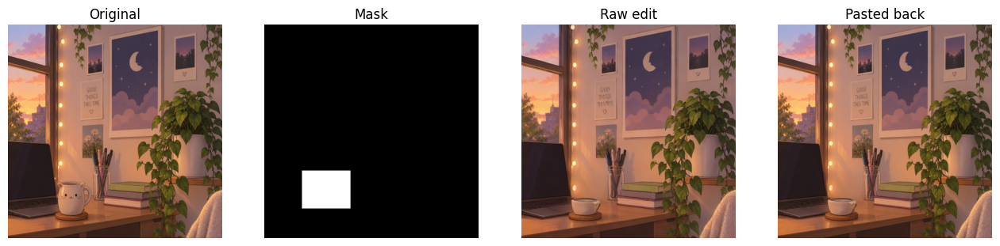

In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter

os.makedirs("/kaggle/working/outputs", exist_ok=True)

# rough box around the mug, adjust these numbers if it misses
mask2 = Image.new("L", (512, 512), 0)
ImageDraw.Draw(mask2).rectangle([90, 350, 205, 440], fill=255)

prompt2 = "a plain blue ceramic mug"
generator = torch.Generator(device).manual_seed(42)

result2 = pipe(
    prompt=prompt2,
    image=image,
    mask_image=mask2,
    num_inference_steps=30,
    generator=generator,
).images[0]

# paste back with a softened edge
soft_mask2 = mask2.filter(ImageFilter.GaussianBlur(4))
final2 = Image.composite(result2, image, soft_mask2)

# measure the change outside the edit area
outside2 = np.array(soft_mask2) == 0
orig_arr = np.array(image).astype(float)
raw_diff2 = np.abs(np.array(result2).astype(float) - orig_arr).mean(axis=2)
final_diff2 = np.abs(np.array(final2).astype(float) - orig_arr).mean(axis=2)
print("Average change outside, raw model output:", round(raw_diff2[outside2].mean(), 3))
print("Average change outside, after paste back:", round(final_diff2[outside2].mean(), 3))

# save the images
image.save("/kaggle/working/outputs/mug_original.png")
mask2.save("/kaggle/working/outputs/mug_mask.png")
result2.save("/kaggle/working/outputs/mug_raw_edit.png")
final2.save("/kaggle/working/outputs/mug_pasted_back.png")

# show and save a side by side comparison
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, img, title in zip(axes, [image, mask2, result2, final2], ["Original", "Mask", "Raw edit", "Pasted back"]):
    ax.imshow(img, cmap="gray" if title == "Mask" else None)
    ax.set_title(title)
    ax.axis("off")
plt.savefig("/kaggle/working/outputs/mug_comparison.png", bbox_inches="tight")
plt.show()

## What the mug edit shows

### What I did
- Masked the mug with a rectangle and prompted "a plain blue ceramic mug"
- Same pipeline as the poster edit: inpaint, paste back with a softened edge, measure change outside the edit area
- Images saved to the outputs folder for the README and storyboards

### Results
- Average change outside, raw model output: 5.451
- Average change outside, after paste back: 0.0
- Edit quality: The mug edit replaced the whole object instead of recolouring it. Testing the strength setting (1.0 redraws the masked area fully, lower values keep more of the original) with the same mask, prompt and seed, so only strength changes.

### What I noticed
- Raw output changed areas outside the mask again, similar to the poster edit (6.086)
- The mug has been swapped out for a simple, diffrent shapped size mug and removed the elements to it like the eyes and has not chaged the colour.

### Limits
- One image and one seed (42), so these are two examples and not a general finding

### Decision
-  Testing the strength setting (1.0 redraws the masked area fully, lower values keep more of the original) with the same mask, prompt and seed, so only strength changes.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/22 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

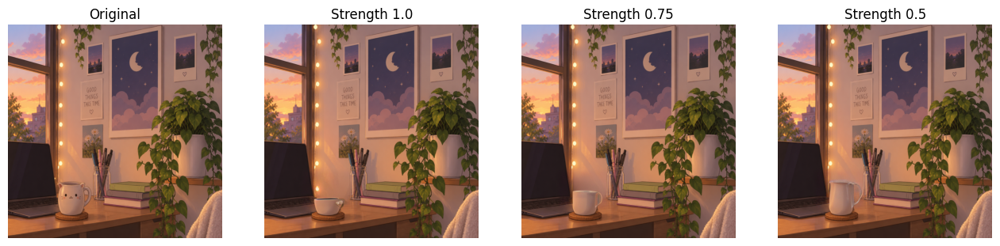

In [9]:
# same mask, prompt and seed, only strength changes
strengths = [1.0, 0.75, 0.5]
prompt3 = "a blue ceramic mug"

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(image)
axes[0].set_title("Original")
axes[0].axis("off")

for i, s in enumerate(strengths):
    generator = torch.Generator(device).manual_seed(42)
    out = pipe(
        prompt=prompt3,
        image=image,
        mask_image=mask2,
        strength=s,
        num_inference_steps=30,
        generator=generator,
    ).images[0]

    # paste back with the same softened mask
    pasted = Image.composite(out, image, soft_mask2)
    pasted.save(f"/kaggle/working/outputs/mug_strength_{s}.png")

    axes[i + 1].imshow(pasted)
    axes[i + 1].set_title(f"Strength {s}")
    axes[i + 1].axis("off")

plt.savefig("/kaggle/working/outputs/mug_strength_comparison.png", bbox_inches="tight")
plt.show()

## What the strength comparison shows

### What I did
- Same mask, prompt ("a blue ceramic mug") and seed (42) for all three runs, changing only strength: 1.0, 0.75 and 0.5
- Pasted each result back with the same softened mask

### Results
- Strength 1.0: small plain white cup
- Strength 0.75: blockier white mug with a handle
- Strength 0.5: taller white jug-like mug
- None turned blue and none kept the original mug's cute face

### What I noticed
- I expected a lower strength to keep more of the original mug. It did not, it only changed the shape of the replacement
- The model redraws the object in its own default style, so the edit does not match the soft, cute look of the rest of the image
- The paste back keeps everything outside the mask identical (0.0), but it cannot fix a mismatch inside the edit

### Limits
- One image, one mask, one seed and one prompt, so this is an example and not a general finding

### Decision
- Recolouring or restyling an existing object is unreliable with this model. For the successful demo, try adding or removing an object instead
- Style matching inside the edit goes in the design as planned, not implemented

## Fifth test: adding an object with a precise prompt

The first add-an-object attempt used a vague prompt. This run uses the same mask and seed (42) but a prompt that describes the object, the style and the lighting of the scene, plus a negative prompt, to see if the edit blends in better. Same pipeline: mask, edit, paste back with a softened edge, measure the change outside the edit area. Files are saved with a v2 name so the first attempt stays as evidence.

  0%|          | 0/30 [00:00<?, ?it/s]

Average change outside, raw model output: 5.214
Average change outside, after paste back: 0.0


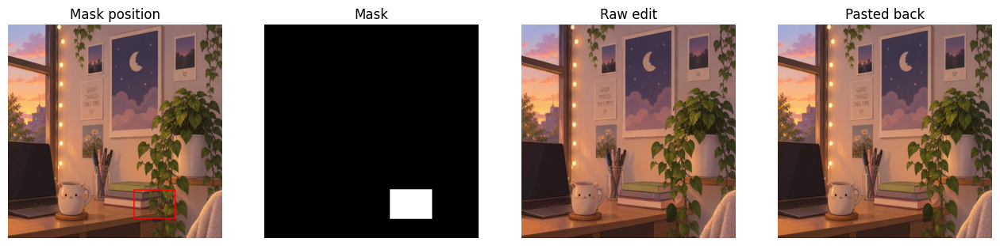

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter

# same box as the first attempt, adjust if it misses
box = [300, 395, 400, 465]

mask4 = Image.new("L", (512, 512), 0)
ImageDraw.Draw(mask4).rectangle(box, fill=255)

# copy of the original with the box outlined in red, to check placement
preview = image.copy()
ImageDraw.Draw(preview).rectangle(box, outline=(255, 0, 0), width=3)

# precise prompt: object, details, style and lighting
prompt4 = "a small green succulent in a round white ceramic pot, sitting on the wooden desk, soft pastel illustration style, warm sunset lighting, cosy"
negative4 = "blurry, text, watermark, realistic photo, harsh shadows"

# same seed as the first attempt so only the prompt changes
generator = torch.Generator(device).manual_seed(42)

result4 = pipe(
    prompt=prompt4,
    negative_prompt=negative4,
    image=image,
    mask_image=mask4,
    num_inference_steps=30,
    generator=generator,
).images[0]

# paste back with a softened edge
soft_mask4 = mask4.filter(ImageFilter.GaussianBlur(4))
final4 = Image.composite(result4, image, soft_mask4)

# measure the change outside the edit area
outside4 = np.array(soft_mask4) == 0
orig_arr = np.array(image).astype(float)
raw_diff4 = np.abs(np.array(result4).astype(float) - orig_arr).mean(axis=2)
final_diff4 = np.abs(np.array(final4).astype(float) - orig_arr).mean(axis=2)
print("Average change outside, raw model output:", round(raw_diff4[outside4].mean(), 3))
print("Average change outside, after paste back:", round(final_diff4[outside4].mean(), 3))

# save the images with v2 names
image.save("/kaggle/working/outputs/add_v2_original.png")
mask4.save("/kaggle/working/outputs/add_v2_mask.png")
result4.save("/kaggle/working/outputs/add_v2_raw_edit.png")
final4.save("/kaggle/working/outputs/add_v2_pasted_back.png")

# show and save a side by side comparison
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, img, title in zip(axes, [preview, mask4, result4, final4], ["Mask position", "Mask", "Raw edit", "Pasted back"]):
    ax.imshow(img, cmap="gray" if title == "Mask" else None)
    ax.set_title(title)
    ax.axis("off")
plt.savefig("/kaggle/working/outputs/add_v2_comparison.png", bbox_inches="tight")
plt.show()

### Checking mask placement and zooming in

The red box landed on the books and plant pot instead of bare desk, so the edit was hard to see. This cell shows the image large with pixel coordinates to pick a better spot, and zooms in on the edit area for the original, raw edit and pasted back versions.

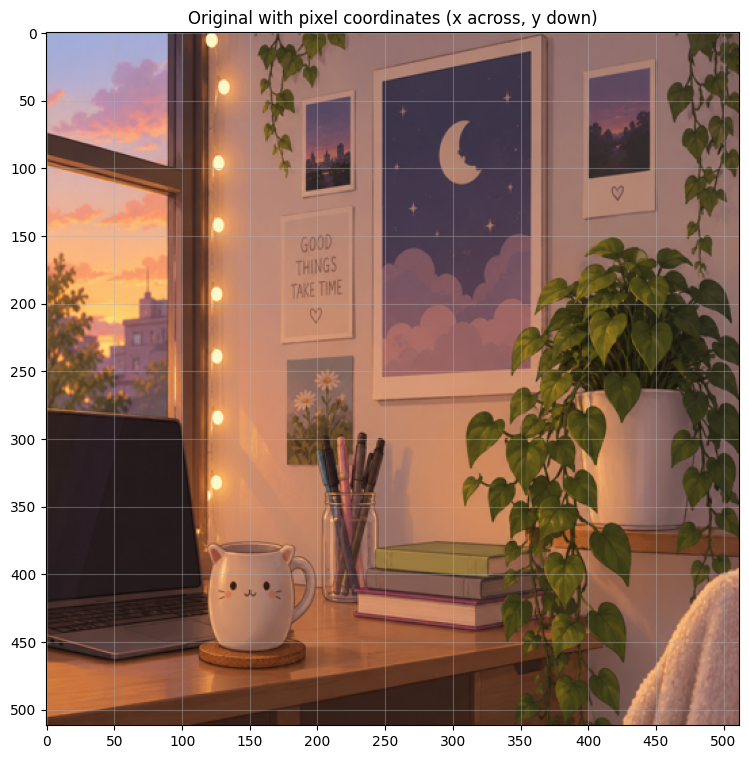

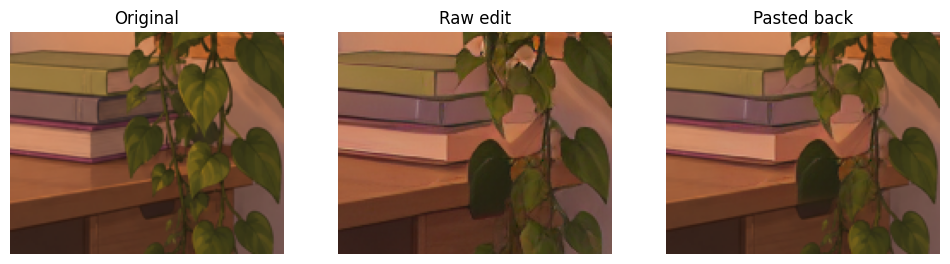

In [12]:
# big view with pixel coordinates, to pick a bare patch of desk
plt.figure(figsize=(9, 9))
plt.imshow(image)
plt.xticks(range(0, 513, 50))
plt.yticks(range(0, 513, 50))
plt.grid(True, alpha=0.4)
plt.title("Original with pixel coordinates (x across, y down)")
plt.show()

# zoom in on the current edit box for each version
left, top, right, bottom = box
pad = 30
crop_area = (max(left - pad, 0), max(top - pad, 0), min(right + pad, 512), min(bottom + pad, 512))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, title in zip(axes, [image, result4, final4], ["Original", "Raw edit", "Pasted back"]):
    ax.imshow(img.crop(crop_area))
    ax.set_title(title)
    ax.axis("off")
plt.show()

### What the placement check showed

- The red box overlapped the lower leaves of the plant and the end of the books, not bare desk
- Prompted for "a small green succulent in a round white ceramic pot", the model removed the leaves and filled the area with background instead of adding an object
- So the edit behaved like object removal and ignored the prompt
- Same result for the raw edit and the pasted back version inside the box. Outside it the paste back kept everything identical (0.0)
- Limit: one image, one mask and one seed (42)
- Decision: move the box to a bare patch of desk and make it larger (about 120 by 80) so the model has empty space to fill

## Sixth test: several options from different seeds

Results change a lot with the seed, so this generates four options for the same mask and prompt, pastes each back, and shows them side by side. The best one is chosen by eye, and the choice is recorded here. Showing several options and letting the user pick is also a possible interface feature.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

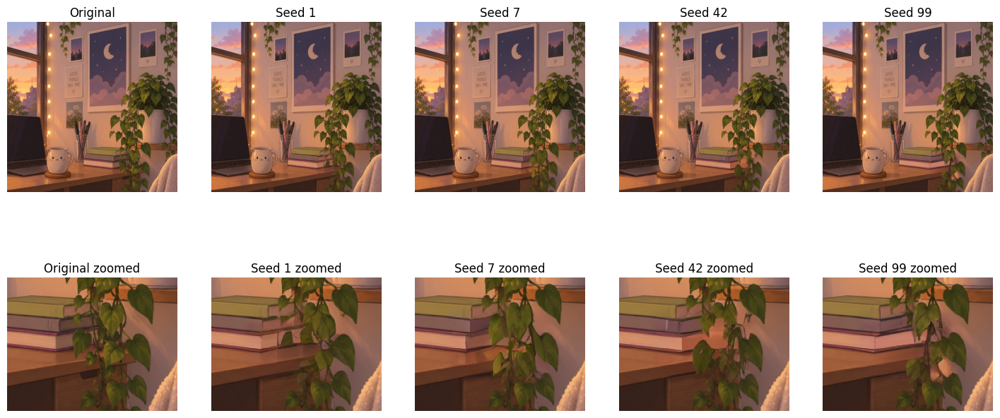

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter

# set this to the area you want to edit (left, top, right, bottom)
box = [300, 395, 420, 475]

mask5 = Image.new("L", (512, 512), 0)
ImageDraw.Draw(mask5).rectangle(box, fill=255)
soft_mask5 = mask5.filter(ImageFilter.GaussianBlur(4))

# for removal, describe the background that should fill the area
prompt5 = "empty wooden desk surface, soft pastel illustration style, warm sunset lighting"
negative5 = "blurry, text, watermark, realistic photo, harsh shadows"

seeds = [1, 7, 42, 99]
left, top, right, bottom = box
pad = 40
crop_area = (max(left - pad, 0), max(top - pad, 0), min(right + pad, 512), min(bottom + pad, 512))

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes[0][0].imshow(image)
axes[0][0].set_title("Original")
axes[1][0].imshow(image.crop(crop_area))
axes[1][0].set_title("Original zoomed")

for i, s in enumerate(seeds):
    generator = torch.Generator(device).manual_seed(s)
    out = pipe(
        prompt=prompt5,
        negative_prompt=negative5,
        image=image,
        mask_image=mask5,
        num_inference_steps=30,
        generator=generator,
    ).images[0]

    # paste back so everything outside the box matches the original
    pasted = Image.composite(out, image, soft_mask5)
    pasted.save(f"/kaggle/working/outputs/options_seed_{s}.png")

    axes[0][i + 1].imshow(pasted)
    axes[0][i + 1].set_title(f"Seed {s}")
    axes[1][i + 1].imshow(pasted.crop(crop_area))
    axes[1][i + 1].set_title(f"Seed {s} zoomed")

for row in axes:
    for ax in row:
        ax.axis("off")

plt.savefig("/kaggle/working/outputs/options_comparison.png", bbox_inches="tight")
plt.show()

## Seventh test: removing the mug, four seeds

The last box overlapped the books and vine, so there was no empty space to fill. This run targets the mug instead, which sits on plain desk. The prompt describes the empty desk that should replace it. Four seeds, each pasted back with a softened edge, shown side by side with zoomed crops. The best option is chosen by eye and recorded below.

  0%|          | 0/30 [00:00<?, ?it/s]

Seed 1 raw change outside: 5.612


  0%|          | 0/30 [00:00<?, ?it/s]

Seed 7 raw change outside: 5.37


  0%|          | 0/30 [00:00<?, ?it/s]

Seed 42 raw change outside: 5.269


  0%|          | 0/30 [00:00<?, ?it/s]

Seed 99 raw change outside: 5.431


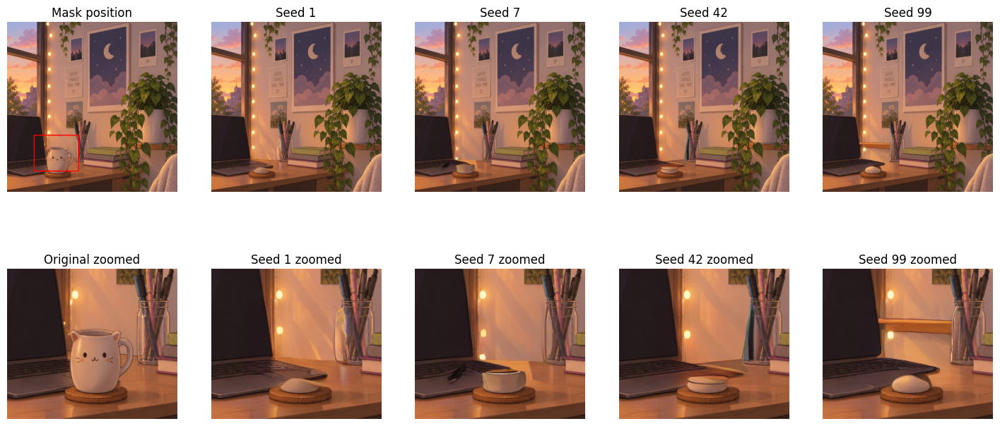

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter

# a little bigger than the mug (left, top, right, bottom), adjust if it misses
box = [80, 340, 215, 450]
prefix = "remove_mug"

mask6 = Image.new("L", (512, 512), 0)
ImageDraw.Draw(mask6).rectangle(box, fill=255)
soft_mask6 = mask6.filter(ImageFilter.GaussianBlur(4))

# describe what should fill the area
prompt6 = "empty wooden desk surface, soft pastel illustration style, warm sunset lighting"
negative6 = "mug, cup, blurry, text, watermark, realistic photo, harsh shadows"

seeds = [1, 7, 42, 99]
left, top, right, bottom = box
pad = 40
crop_area = (max(left - pad, 0), max(top - pad, 0), min(right + pad, 512), min(bottom + pad, 512))

# original with the box outlined in red, to check placement
preview = image.copy()
ImageDraw.Draw(preview).rectangle(box, outline=(255, 0, 0), width=3)

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes[0][0].imshow(preview)
axes[0][0].set_title("Mask position")
axes[1][0].imshow(image.crop(crop_area))
axes[1][0].set_title("Original zoomed")

orig_arr = np.array(image).astype(float)
outside6 = np.array(soft_mask6) == 0

for i, s in enumerate(seeds):
    generator = torch.Generator(device).manual_seed(s)
    out = pipe(
        prompt=prompt6,
        negative_prompt=negative6,
        image=image,
        mask_image=mask6,
        num_inference_steps=30,
        generator=generator,
    ).images[0]

    # paste back so everything outside the box matches the original
    pasted = Image.composite(out, image, soft_mask6)
    pasted.save(f"/kaggle/working/outputs/{prefix}_seed_{s}.png")

    raw_change = np.abs(np.array(out).astype(float) - orig_arr).mean(axis=2)[outside6].mean()
    print("Seed", s, "raw change outside:", round(raw_change, 3))

    axes[0][i + 1].imshow(pasted)
    axes[0][i + 1].set_title(f"Seed {s}")
    axes[1][i + 1].imshow(pasted.crop(crop_area))
    axes[1][i + 1].set_title(f"Seed {s} zoomed")

for row in axes:
    for ax in row:
        ax.axis("off")

plt.savefig(f"/kaggle/working/outputs/{prefix}_comparison.png", bbox_inches="tight")
plt.show()

## Eighth test: retrying the mug removal

The first removal attempt turned the mug into a blob. This retry changes three things: a larger mask so the whole mug and a margin are covered, a simpler prompt with no mug words in the negative prompt, and padding_mask_crop so the model works on a zoomed-in version of the edit area. Four seeds again, pasted back and shown with zoomed crops.

  0%|          | 0/30 [00:00<?, ?it/s]

Seed 1 raw change outside: 0.0


  0%|          | 0/30 [00:00<?, ?it/s]

Seed 7 raw change outside: 0.0


  0%|          | 0/30 [00:00<?, ?it/s]

Seed 42 raw change outside: 0.0


  0%|          | 0/30 [00:00<?, ?it/s]

Seed 99 raw change outside: 0.0


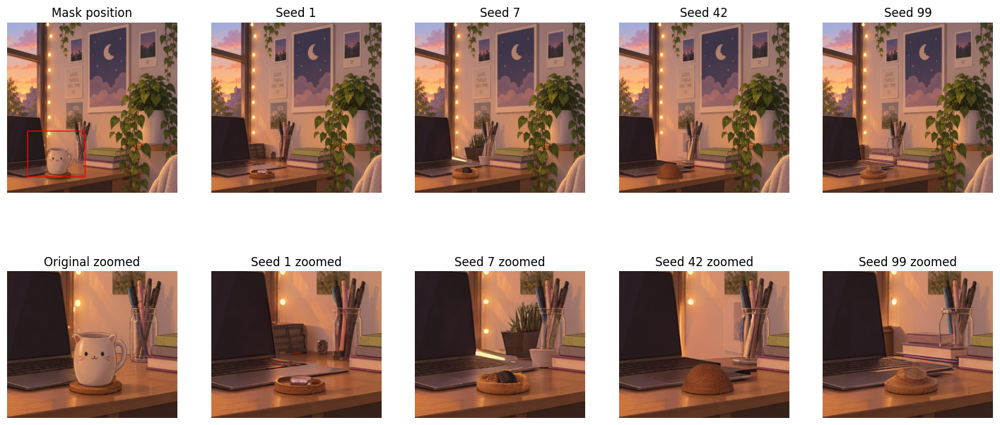

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter

# bigger box with a margin around the mug (left, top, right, bottom)
box = [60, 325, 235, 465]
prefix = "remove_mug_v2"

mask7 = Image.new("L", (512, 512), 0)
ImageDraw.Draw(mask7).rectangle(box, fill=255)
soft_mask7 = mask7.filter(ImageFilter.GaussianBlur(6))

# simpler prompt, no mug words in the negative prompt
prompt7 = "plain wooden desk surface"
negative7 = "blurry, text, watermark"

seeds = [1, 7, 42, 99]
left, top, right, bottom = box
pad = 40
crop_area = (max(left - pad, 0), max(top - pad, 0), min(right + pad, 512), min(bottom + pad, 512))

preview = image.copy()
ImageDraw.Draw(preview).rectangle(box, outline=(255, 0, 0), width=3)

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes[0][0].imshow(preview)
axes[0][0].set_title("Mask position")
axes[1][0].imshow(image.crop(crop_area))
axes[1][0].set_title("Original zoomed")

orig_arr = np.array(image).astype(float)
outside7 = np.array(soft_mask7) == 0

for i, s in enumerate(seeds):
    generator = torch.Generator(device).manual_seed(s)
    out = pipe(
        prompt=prompt7,
        negative_prompt=negative7,
        image=image,
        mask_image=mask7,
        padding_mask_crop=48,
        num_inference_steps=30,
        generator=generator,
    ).images[0]

    pasted = Image.composite(out, image, soft_mask7)
    pasted.save(f"/kaggle/working/outputs/{prefix}_seed_{s}.png")

    raw_change = np.abs(np.array(out).astype(float) - orig_arr).mean(axis=2)[outside7].mean()
    print("Seed", s, "raw change outside:", round(raw_change, 3))

    axes[0][i + 1].imshow(pasted)
    axes[0][i + 1].set_title(f"Seed {s}")
    axes[1][i + 1].imshow(pasted.crop(crop_area))
    axes[1][i + 1].set_title(f"Seed {s} zoomed")

for row in axes:
    for ax in row:
        ax.axis("off")

plt.savefig(f"/kaggle/working/outputs/{prefix}_comparison.png", bbox_inches="tight")
plt.show()

### What I noticed
- The brown item appeared in all four seeds, so it looks driven by the surrounding context (a coaster on a wooden desk) and not by the seed
- The raw change is 0.0 because padding_mask_crop works on a zoomed crop and pastes it back itself. So this run cannot show leakage, and the leakage numbers come from the earlier runs (6.086, 5.451, 5.214)
- The first attempt, with a tight mask and no padding_mask_crop, gave a blob, so mask size and padding_mask_crop seem to matter for removal

### Decisions
- Treat this as a partial success for storyboard 1: the mug was removed, but the model added something I did not ask for, so the user needs the preview and undo
- Keep the poster text, the recoloured mug and the blob as "AI gets it wrong" examples
- Use padding_mask_crop in the prototype

## Ninth test: three targeted edits, four seeds each

Aiming at what inpainting does well: removal and filling empty space. Each edit has a mask with a margin, a prompt that describes what should be there, a negative prompt for what should not, padding_mask_crop and four seeds, pasted back with a softened edge. The best seed for each is chosen by eye and recorded below. Files are saved with the edit name as a prefix.

- coaster_empty: retry of the mug removal, asking for an empty coaster
- add_succulent: adding a plant to a bare strip of desk
- leaves_removed: removing the hanging leaves over the books

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

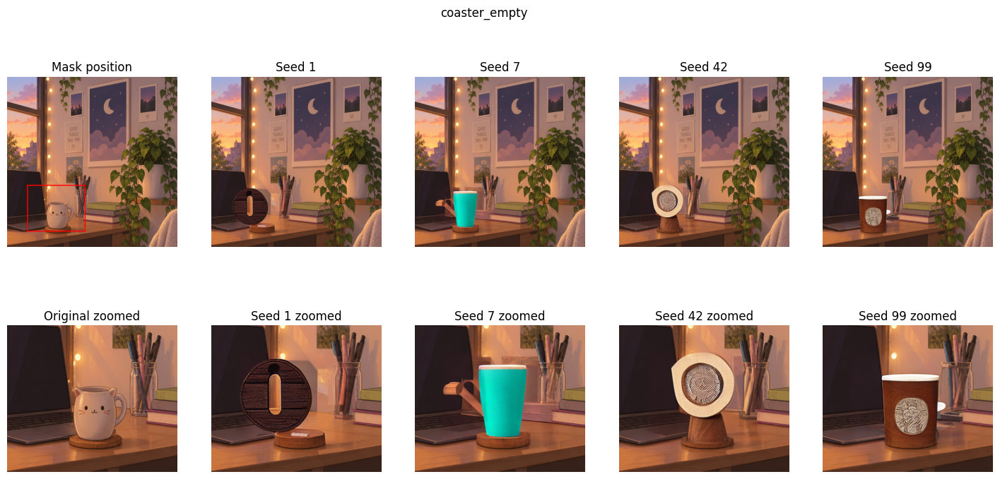

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

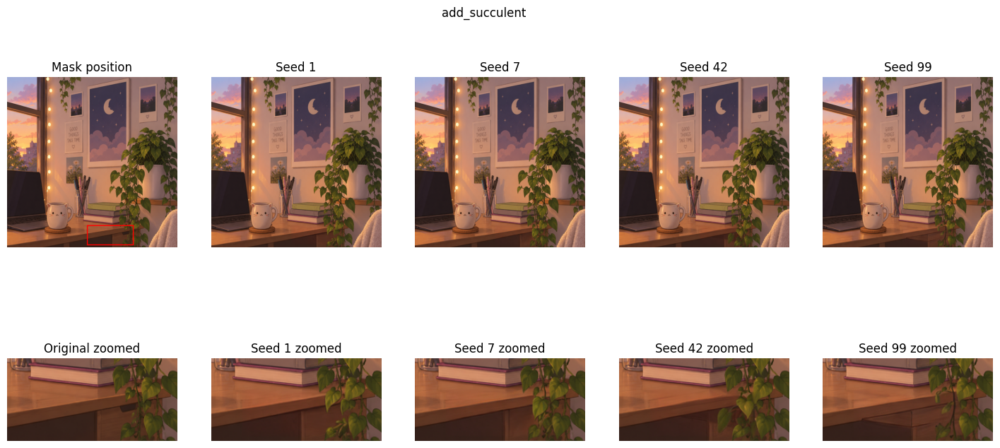

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

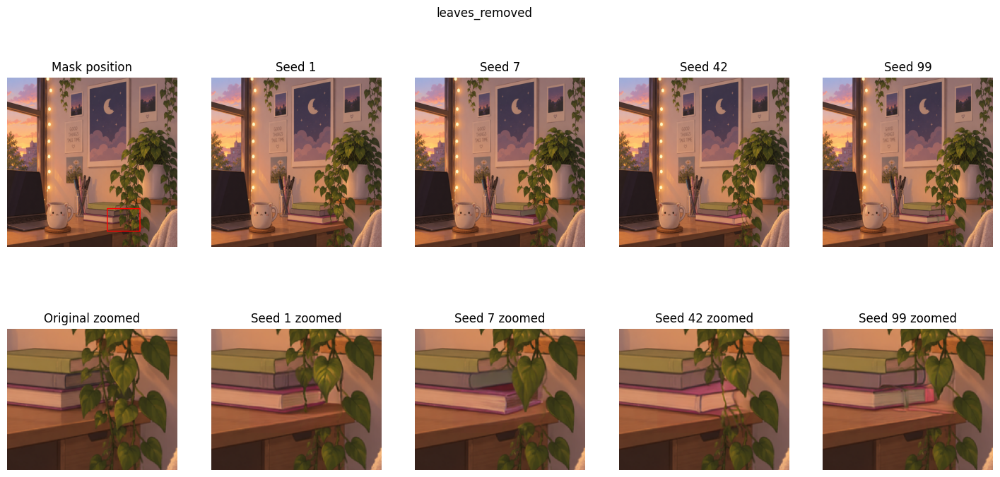

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter

def run_edit(name, box, prompt, negative, seeds=(1, 7, 42, 99)):
    mask = Image.new("L", (512, 512), 0)
    ImageDraw.Draw(mask).rectangle(box, fill=255)
    soft = mask.filter(ImageFilter.GaussianBlur(6))

    left, top, right, bottom = box
    pad = 40
    crop_area = (max(left - pad, 0), max(top - pad, 0), min(right + pad, 512), min(bottom + pad, 512))

    # original with the box outlined in red, to check placement
    preview = image.copy()
    ImageDraw.Draw(preview).rectangle(box, outline=(255, 0, 0), width=3)

    fig, axes = plt.subplots(2, len(seeds) + 1, figsize=(18, 8))
    axes[0][0].imshow(preview)
    axes[0][0].set_title("Mask position")
    axes[1][0].imshow(image.crop(crop_area))
    axes[1][0].set_title("Original zoomed")

    for i, s in enumerate(seeds):
        generator = torch.Generator(device).manual_seed(s)
        out = pipe(
            prompt=prompt,
            negative_prompt=negative,
            image=image,
            mask_image=mask,
            padding_mask_crop=48,
            num_inference_steps=30,
            generator=generator,
        ).images[0]

        pasted = Image.composite(out, image, soft)
        pasted.save(f"/kaggle/working/outputs/{name}_seed_{s}.png")

        axes[0][i + 1].imshow(pasted)
        axes[0][i + 1].set_title(f"Seed {s}")
        axes[1][i + 1].imshow(pasted.crop(crop_area))
        axes[1][i + 1].set_title(f"Seed {s} zoomed")

    for row in axes:
        for ax in row:
            ax.axis("off")
    plt.suptitle(name)
    plt.savefig(f"/kaggle/working/outputs/{name}_comparison.png", bbox_inches="tight")
    plt.show()

# edit 1: mug removal again, asking for an empty coaster
run_edit(
    "coaster_empty",
    [60, 325, 235, 465],
    "an empty round wooden coaster on a wooden desk",
    "bowl, dome, food, object, blurry, text",
)

# edit 2: add a plant to a bare strip of desk (move the box if it lands on something)
run_edit(
    "add_succulent",
    [240, 445, 380, 505],
    "a small green succulent in a round white ceramic pot on the wooden desk, soft pastel illustration style, warm sunset lighting",
    "blurry, text, watermark, realistic photo",
)

# edit 3: remove the hanging leaves over the books
run_edit(
    "leaves_removed",
    [300, 395, 400, 465],
    "a stack of books on a wooden desk, soft pastel illustration style, warm sunset lighting",
    "plant, leaves, vine, blurry, text",
)

## Tenth test: tighter masks, minimal prompts, lower guidance

The ninth test failed. The mug box was too big and the prompt mentioned a coaster, so the model drew new cups. The succulent box landed on the front edge of the desk, and the leaf box only covered part of the leaves. This run uses tighter masks, prompts that only describe the background, a lower guidance scale (4, default is 7.5) and a plainer target, the small note on the wall. The failed ninth test files are kept as "AI gets it wrong" evidence.

  0%|          | 0/30 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


  0%|          | 0/30 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

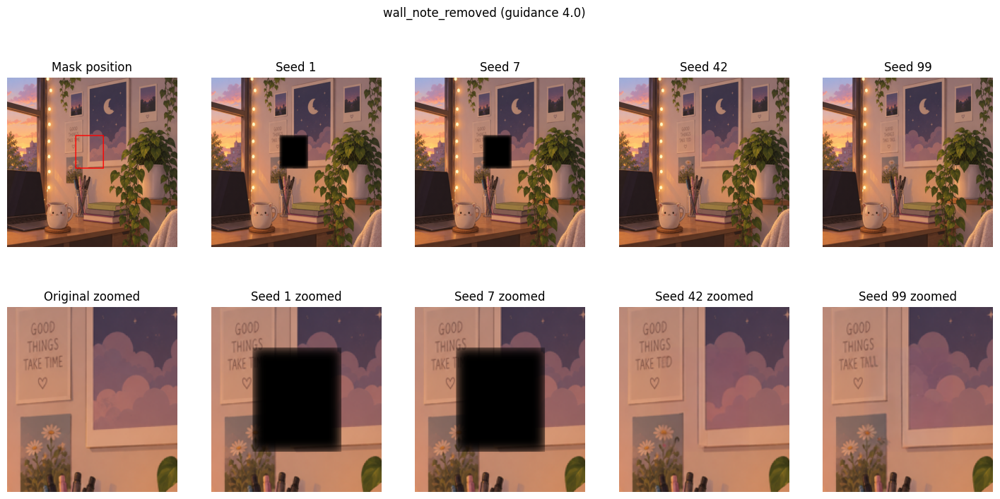

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

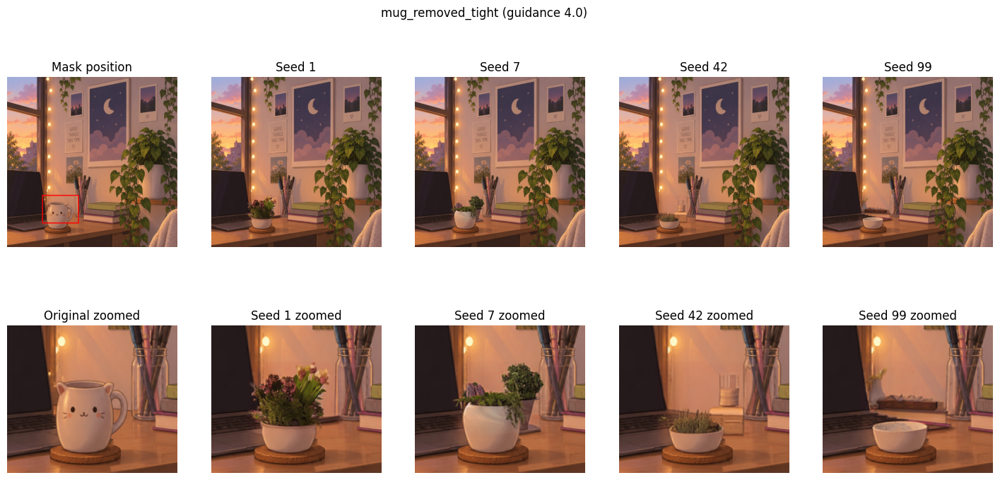

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter

def run_edit(name, box, prompt, negative, guidance=4.0, seeds=(1, 7, 42, 99)):
    mask = Image.new("L", (512, 512), 0)
    ImageDraw.Draw(mask).rectangle(box, fill=255)
    soft = mask.filter(ImageFilter.GaussianBlur(5))

    left, top, right, bottom = box
    pad = 40
    crop_area = (max(left - pad, 0), max(top - pad, 0), min(right + pad, 512), min(bottom + pad, 512))

    # original with the box outlined in red, to check placement
    preview = image.copy()
    ImageDraw.Draw(preview).rectangle(box, outline=(255, 0, 0), width=3)

    fig, axes = plt.subplots(2, len(seeds) + 1, figsize=(18, 8))
    axes[0][0].imshow(preview)
    axes[0][0].set_title("Mask position")
    axes[1][0].imshow(image.crop(crop_area))
    axes[1][0].set_title("Original zoomed")

    for i, s in enumerate(seeds):
        generator = torch.Generator(device).manual_seed(s)
        out = pipe(
            prompt=prompt,
            negative_prompt=negative,
            image=image,
            mask_image=mask,
            padding_mask_crop=32,
            guidance_scale=guidance,
            num_inference_steps=30,
            generator=generator,
        ).images[0]

        pasted = Image.composite(out, image, soft)
        pasted.save(f"/kaggle/working/outputs/{name}_seed_{s}.png")

        axes[0][i + 1].imshow(pasted)
        axes[0][i + 1].set_title(f"Seed {s}")
        axes[1][i + 1].imshow(pasted.crop(crop_area))
        axes[1][i + 1].set_title(f"Seed {s} zoomed")

    for row in axes:
        for ax in row:
            ax.axis("off")
    plt.suptitle(f"{name} (guidance {guidance})")
    plt.savefig(f"/kaggle/working/outputs/{name}_comparison.png", bbox_inches="tight")
    plt.show()

# edit 1: remove the small note on the left wall, plain wall behind it
run_edit(
    "wall_note_removed",
    [205, 175, 290, 275],
    "plain wall",
    "paper, poster, frame, text, object",
)

# edit 2: remove just the mug, tighter box, minimal prompt
run_edit(
    "mug_removed_tight",
    [105, 355, 215, 440],
    "wooden desk",
    "cup, mug, bowl, object, text",
)

## Eleventh test: LaMa for removal

Stable Diffusion inpainting kept inventing objects in the mug area (plants, bowls, cups) because it fills holes with something plausible. LaMa is built for removal and fills with surrounding background instead. Same mask as the tight mug test, grown slightly so no edge of the mug is left behind, then pasted back with a softened edge.

Also noting: two seeds in the wall note test came back black. This looks like the Stable Diffusion safety checker flagging a harmless image by mistake, so it is switched off for this scene.

In [19]:
# install LaMa without its pinned old Pillow, then add what it needs
!pip install -q --no-deps simple-lama-inpainting
!pip install -q opencv-python-headless fire

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
simple-lama-inpainting 0.1.2 requires fire<0.6.0,>=0.5.0, but you have fire 0.7.1 which is incompatible.
simple-lama-inpainting 0.1.2 requires numpy<2.0.0,>=1.24.3, but you have numpy 2.1.3 which is incompatible.
simple-lama-inpainting 0.1.2 requires pillow<10.0.0,>=9.5.0, but you have pillow 13.0.0 which is incompatible.


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'pillow' when getting requirements to build wheel


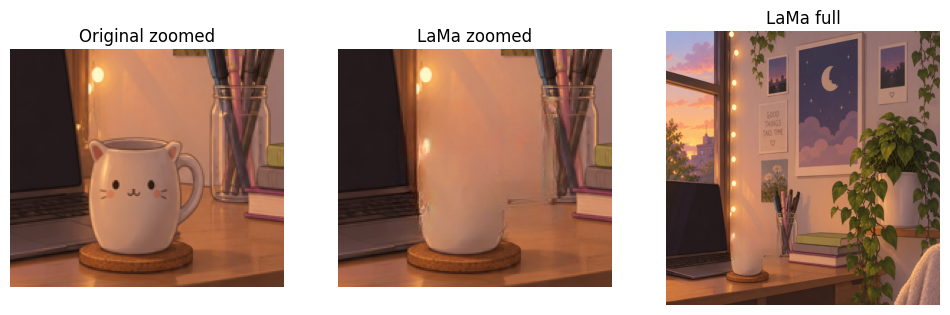

In [22]:
# switch off the safety checker (it blacked out two harmless images)
pipe.safety_checker = None

# install and load LaMa (needs internet on in Kaggle)
!pip install -q simple-lama-inpainting

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter
from simple_lama_inpainting import SimpleLama

lama = SimpleLama()

def lama_remove(name, box, grow=6):
    mask = Image.new("L", (512, 512), 0)
    ImageDraw.Draw(mask).rectangle(box, fill=255)
    # grow the mask slightly so no edge of the object is left behind
    mask = mask.filter(ImageFilter.MaxFilter(2 * grow + 1))

    out = lama(image, mask).convert("RGB").resize((512, 512))

    # paste back with a softened edge
    soft = mask.filter(ImageFilter.GaussianBlur(4))
    pasted = Image.composite(out, image, soft)
    pasted.save(f"/kaggle/working/outputs/{name}_lama.png")

    left, top, right, bottom = box
    pad = 40
    crop_area = (max(left - pad, 0), max(top - pad, 0), min(right + pad, 512), min(bottom + pad, 512))

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, img, title in zip(axes, [image.crop(crop_area), pasted.crop(crop_area), pasted], ["Original zoomed", "LaMa zoomed", "LaMa full"]):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")
    plt.savefig(f"/kaggle/working/outputs/{name}_lama_comparison.png", bbox_inches="tight")
    plt.show()

# same box as the tight mug test
lama_remove("mug_removed_tight", [105, 355, 215, 440])

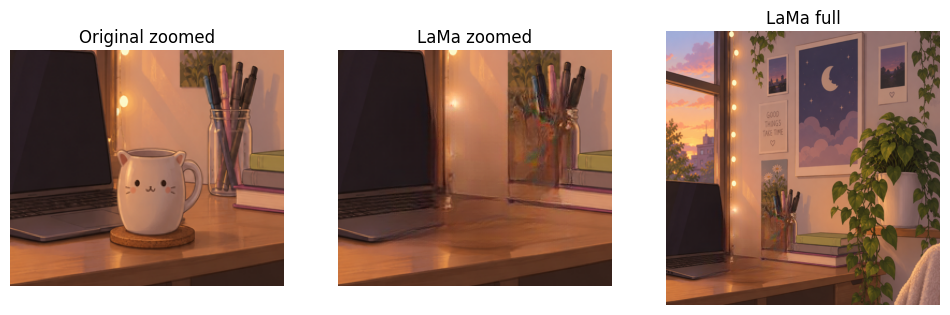

In [23]:
lama_remove("wall_note_removed", [left, top, right, bottom])

## What LaMa shows for removal

### What I did
- Removed the mug with LaMa and pasted the result back with a softened edge
- Two box sizes: a tight box around the mug, then a larger box covering the mug, the coaster and a margin
- Turned off the Stable Diffusion safety checker after it blacked out two harmless images

### Results
- Stable Diffusion inpainting never removed the mug cleanly. Every attempt invented something (plants, bowls, cups, a brown item)
- LaMa with the tight box removed the mug but left a pale ghost of it and part of the coaster
- LaMa with the larger box removed the mug and coaster fully and filled the area with smooth wood
- The larger box also reached the edge of the pen pot, which looks slightly hazy in the result

### What I noticed
- Stable Diffusion fills a hole with something plausible, so it is a poor fit for pure removal
- LaMa fills with the surrounding background, which is what removal needs
- Mask size mattered: too tight left a ghost, a margin around the object fixed it
- Different models suit different requests: a removal model for "take this out", generative inpainting for "add or change this"

### Limits
- One image and two masks, so this is an example and not a general finding
- Judged by eye with no scoring

### Decisions
- The prototype routes removal to LaMa and add or change edits to Stable Diffusion inpainting
- Use a mask with a margin for removal
- Use the larger-box LaMa result as the successful example for storyboard 1
- Keep the Stable Diffusion removal attempts as "AI gets it wrong" examples

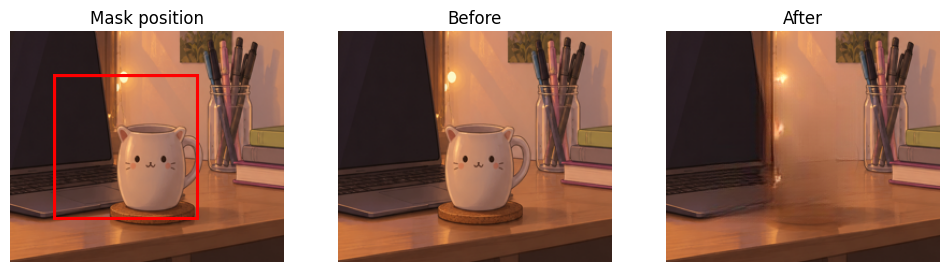

['coaster_empty_seed_7.png', 'add_succulent_comparison.png', 'mug_coaster_removed_lama_comparison.png', 'options_seed_42.png', 'remove_mug_seed_99.png', 'mug_strength_1.0.png', 'mug_removed_tight_seed_7.png', 'add_original.png', 'leaves_removed_seed_1.png', 'leaves_removed_comparison.png', 'remove_mug_seed_7.png', 'wall_note_removed_seed_1.png', 'mug_coaster_removed_lama.png', 'mug_strength_0.5.png', 'remove_mug_v2_seed_7.png', 'add_comparison.png', 'add_succulent_seed_99.png', 'mug_strength_0.75.png', 'options_seed_1.png', 'leaves_removed_seed_7.png', 'remove_mug_v2_seed_1.png', 'mug_removed_tight_comparison.png', 'wall_note_removed_comparison.png', 'add_v2_pasted_back.png', 'add_v2_mask.png', 'wall_note_removed_seed_42.png', 'add_mask.png', 'remove_mug_v2_comparison.png', 'add_v2_comparison.png', 'remove_mug_v2_seed_99.png', 'options_seed_7.png', 'add_v2_original.png', 'mug_original.png', 'coaster_empty_seed_42.png', 'mug_removed_tight_lama_comparison.png', 'wall_note_removed_seed_99

In [29]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter

os.makedirs("/kaggle/working/outputs", exist_ok=True)

# right edge pulled in to try to keep the pen pot out (left, top, right, bottom)
box = [60, 330, 195, 465]

mask = Image.new("L", (512, 512), 0)
ImageDraw.Draw(mask).rectangle(box, fill=255)
mask = mask.filter(ImageFilter.MaxFilter(13))

out = lama(image, mask).convert("RGB").resize((512, 512))
soft = mask.filter(ImageFilter.GaussianBlur(4))
base = Image.composite(out, image, soft)
base.save("/kaggle/working/outputs/mug_coaster_removed_lama.png")

# show the box and the result, zoomed
left, top, right, bottom = box
crop_area = (max(left - 40, 0), max(top - 40, 0), min(right + 80, 512), min(bottom + 40, 512))
preview = image.copy()
ImageDraw.Draw(preview).rectangle(box, outline=(255, 0, 0), width=3)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, title in zip(axes, [preview.crop(crop_area), image.crop(crop_area), base.crop(crop_area)], ["Mask position", "Before", "After"]):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
plt.savefig("/kaggle/working/outputs/mug_coaster_removed_lama_comparison.png", bbox_inches="tight")
plt.show()

# list what is saved so far
print(os.listdir("/kaggle/working/outputs"))

## Twelfth test: SDXL inpainting, adding an object to the cleared desk

Stable Diffusion 1.5 struggled to match the style of the scene and invented objects. This section switches to the SDXL inpainting model, which is larger and follows prompts and style better. The base image is the LaMa mug removal result, so this is a remove-then-add edit: the bare desk patch is filled with a new object. Four seeds, pasted back with a softened edge, with zoomed crops. The red box shows the mask position.

### Pen pot leakage in the removal

- The larger LaMa box reached the pen pot and changed its colour, so the removal was a partial success
- Decision: narrow the right edge of the box to keep the pot out, and note the trade-off between a margin that removes the ghost and one that stays off neighbouring objects

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

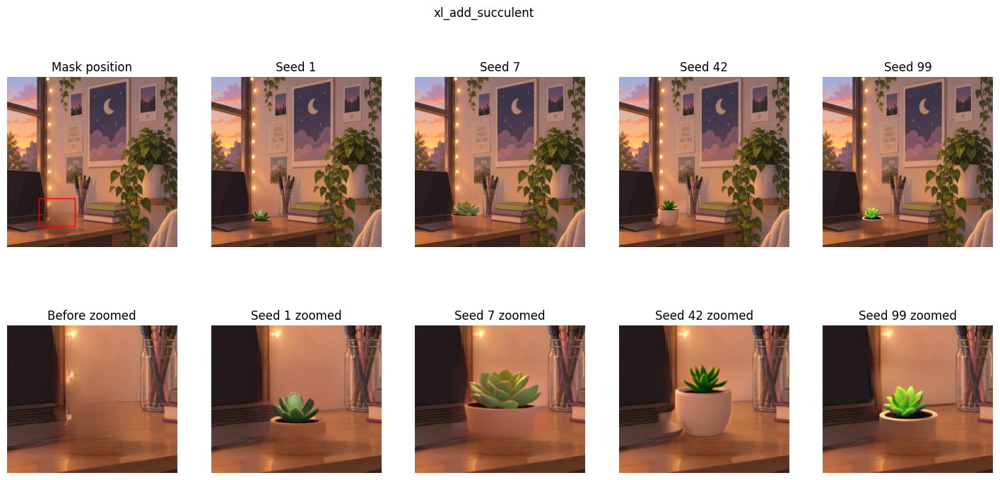

In [30]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter

# base image is the LaMa result with the mug and coaster removed
base = Image.open("/kaggle/working/outputs/mug_coaster_removed_lama.png").convert("RGB").resize((512, 512))

def run_edit_xl(name, base_img, box, prompt, negative, seeds=(1, 7, 42, 99), guidance=7.5):
    # masks are made at 512 and scaled up to 1024 for SDXL
    mask512 = Image.new("L", (512, 512), 0)
    ImageDraw.Draw(mask512).rectangle(box, fill=255)
    soft512 = mask512.filter(ImageFilter.GaussianBlur(5))

    base_big = base_img.resize((1024, 1024))
    mask_big = mask512.resize((1024, 1024))

    left, top, right, bottom = box
    pad = 40
    crop_area = (max(left - pad, 0), max(top - pad, 0), min(right + pad, 512), min(bottom + pad, 512))

    # base image with the box outlined in red, to check placement
    preview = base_img.copy()
    ImageDraw.Draw(preview).rectangle(box, outline=(255, 0, 0), width=3)

    fig, axes = plt.subplots(2, len(seeds) + 1, figsize=(18, 8))
    axes[0][0].imshow(preview)
    axes[0][0].set_title("Mask position")
    axes[1][0].imshow(base_img.crop(crop_area))
    axes[1][0].set_title("Before zoomed")

    for i, s in enumerate(seeds):
        generator = torch.Generator(device).manual_seed(s)
        out = pipe_xl(
            prompt=prompt,
            negative_prompt=negative,
            image=base_big,
            mask_image=mask_big,
            padding_mask_crop=64,
            guidance_scale=guidance,
            num_inference_steps=30,
            generator=generator,
        ).images[0]

        # scale back to 512 and paste back so everything outside the box matches
        out512 = out.resize((512, 512))
        pasted = Image.composite(out512, base_img, soft512)
        pasted.save(f"/kaggle/working/outputs/{name}_seed_{s}.png")

        axes[0][i + 1].imshow(pasted)
        axes[0][i + 1].set_title(f"Seed {s}")
        axes[1][i + 1].imshow(pasted.crop(crop_area))
        axes[1][i + 1].set_title(f"Seed {s} zoomed")

    for row in axes:
        for ax in row:
            ax.axis("off")
    plt.suptitle(name)
    plt.savefig(f"/kaggle/working/outputs/{name}_comparison.png", bbox_inches="tight")
    plt.show()

# add a plant where the mug was (box is a guess, check the red box)
run_edit_xl(
    "xl_add_succulent",
    base,
    [95, 365, 205, 450],
    "a small green succulent in a round white ceramic pot on a wooden desk, soft pastel illustration style, warm sunset lighting",
    "blurry, text, watermark, realistic photo, harsh shadows",
)

### What the SDXL object test showed

- SDXL added a small succulent in a white pot in all four seeds, and the style and lighting matched the scene much better than Stable Diffusion 1.5 did
- The result looked soft because the plant was drawn over the smeared LaMa patch, and the image was only 512 by 512
- Decision: skip the removal step and replace the mug directly with SDXL on the original image

## Thirteenth test: SDXL replacing the mug directly

The remove-then-add version looked blurry, because the plant was drawn on top of the smeared LaMa patch. This run skips LaMa and uses the original image, with a box covering the mug and coaster, so SDXL replaces the mug with a plant in one step. Same four seeds, pasted back with a softened edge.

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

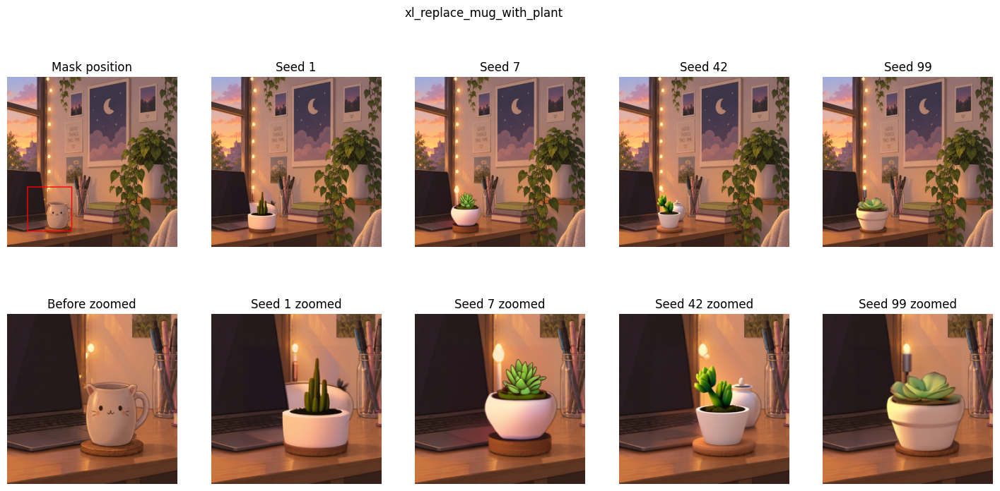

In [31]:
# use the original image, not the LaMa result
run_edit_xl(
    "xl_replace_mug_with_plant",
    image,
    [60, 330, 195, 465],
    "a small green succulent in a round white ceramic pot on a wooden desk, soft pastel illustration style, warm sunset lighting",
    "blurry, text, watermark, realistic photo, harsh shadows, mug, cup",
)

## Fourteenth test: matching the art style

The SDXL plant edit got the object right, but it looked glossy and 3D next to the soft, flat illustrated look of the scene. This run keeps the same mask and seeds, but the prompt names the flat illustrated style, the negative prompt rules out the glossy 3D look, and guidance is lowered from 7.5 to 5.5 so the model leans more on the surrounding image. Saved under a new name so the first version stays as the comparison.

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

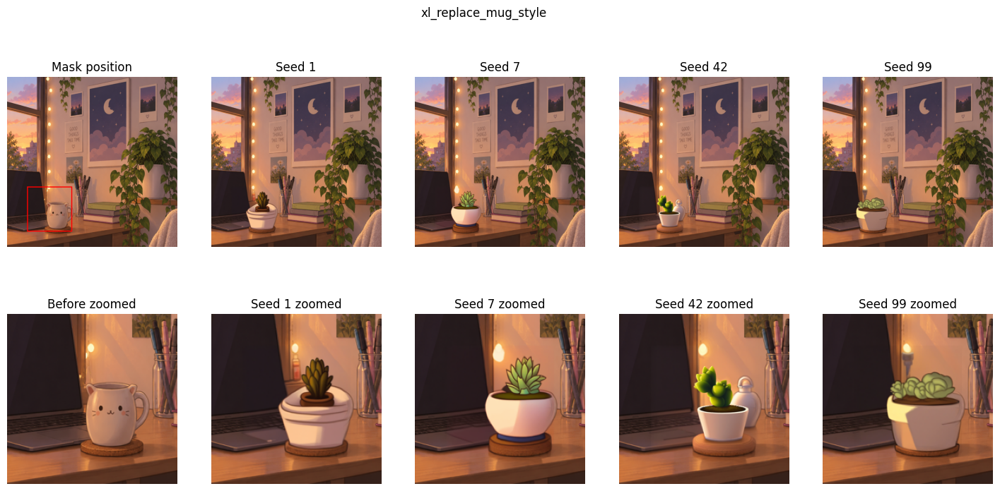

In [32]:
run_edit_xl(
    "xl_replace_mug_style",
    image,
    [60, 330, 195, 465],
    "a small succulent in a cute round white pot on a wooden desk, soft flat cartoon illustration, matching the style of the scene, painted shading, warm sunset glow",
    "3d render, glossy, shiny, photorealistic, realistic photo, blurry, text, watermark, mug, cup",
    guidance=5.5,
)

## What the SDXL mug replacement shows

### What I did
- Replaced the mug and coaster area with a succulent using SDXL inpainting on the original image, with four seeds, pasted back with a softened edge
- This followed a remove-then-add attempt (LaMa then SDXL) that looked soft and smeared, because the plant was drawn over the smeared LaMa patch

### Results
- All four seeds gave a clean plant in a white pot sitting on the coaster, with no smear around it
- Content matched the request well, but the plant looked glossy and 3D next to the soft, flat illustrated scene
- The candle glow behind the mug position is now visible above the plant, which may be original scene content that the mug used to hide

### What I noticed
- Doing the swap in one step worked better than stacking two edits
- SDXL matched the style and lighting much better than Stable Diffusion 1.5, but not perfectly
- A small shift in the prompt and the seed changes the plant a lot (cactus, round succulent, flat-leaved plant)

### Limits
- One image, one mask, four seeds, judged by eye

### Decisions
- Use this as the object edit and swap example for the storyboards
- Offer several options with different seeds, with preview and undo
- Style matching is only partly solved, so a proper style-matching step is marked as planned

### What the style retry showed

- Naming the flat illustrated style in the prompt, ruling out the glossy 3D look and lowering guidance from 7.5 to 5.5 gave slightly flatter, softer plants
- The match is still not perfect, so style matching stays marked as planned
- Seeds 7 and 99 look the best, judged by eye

## Fifteenth test: recolouring the books with SDXL

An edit that keeps the object and changes one property. The box covers the book stack, and the prompt asks for pastel pink and lavender books. Strength is lowered to 0.75 so more of the original shapes survive. Four seeds, pasted back with a softened edge, saved under a new name.

  0%|          | 0/22 [00:00<?, ?it/s]

  0%|          | 0/22 [00:00<?, ?it/s]

  0%|          | 0/22 [00:00<?, ?it/s]

  0%|          | 0/22 [00:00<?, ?it/s]

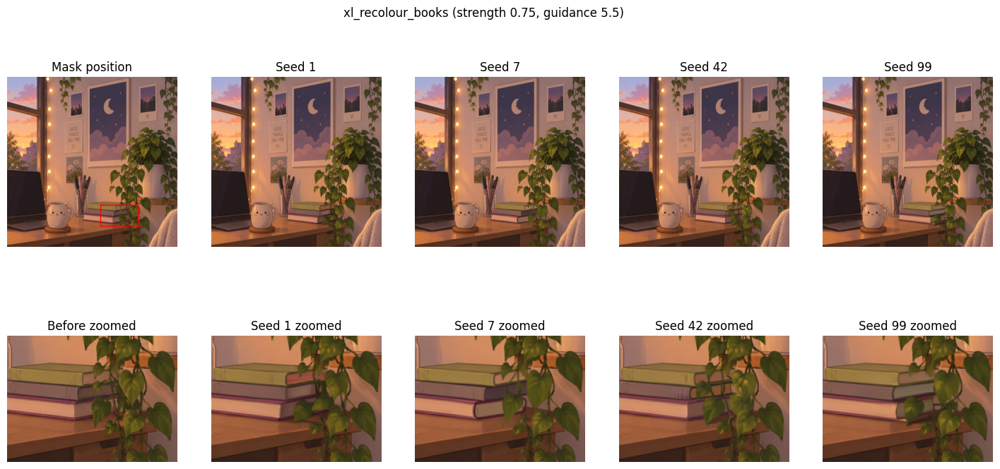

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter

def run_edit_xl(name, base_img, box, prompt, negative, seeds=(1, 7, 42, 99), guidance=7.5, strength=1.0):
    mask512 = Image.new("L", (512, 512), 0)
    ImageDraw.Draw(mask512).rectangle(box, fill=255)
    soft512 = mask512.filter(ImageFilter.GaussianBlur(5))

    base_big = base_img.resize((1024, 1024))
    mask_big = mask512.resize((1024, 1024))

    left, top, right, bottom = box
    pad = 40
    crop_area = (max(left - pad, 0), max(top - pad, 0), min(right + pad, 512), min(bottom + pad, 512))

    preview = base_img.copy()
    ImageDraw.Draw(preview).rectangle(box, outline=(255, 0, 0), width=3)

    fig, axes = plt.subplots(2, len(seeds) + 1, figsize=(18, 8))
    axes[0][0].imshow(preview)
    axes[0][0].set_title("Mask position")
    axes[1][0].imshow(base_img.crop(crop_area))
    axes[1][0].set_title("Before zoomed")

    for i, s in enumerate(seeds):
        generator = torch.Generator(device).manual_seed(s)
        out = pipe_xl(
            prompt=prompt,
            negative_prompt=negative,
            image=base_big,
            mask_image=mask_big,
            padding_mask_crop=64,
            guidance_scale=guidance,
            strength=strength,
            num_inference_steps=30,
            generator=generator,
        ).images[0]

        out512 = out.resize((512, 512))
        pasted = Image.composite(out512, base_img, soft512)
        pasted.save(f"/kaggle/working/outputs/{name}_seed_{s}.png")

        axes[0][i + 1].imshow(pasted)
        axes[0][i + 1].set_title(f"Seed {s}")
        axes[1][i + 1].imshow(pasted.crop(crop_area))
        axes[1][i + 1].set_title(f"Seed {s} zoomed")

    for row in axes:
        for ax in row:
            ax.axis("off")
    plt.suptitle(f"{name} (strength {strength}, guidance {guidance})")
    plt.savefig(f"/kaggle/working/outputs/{name}_comparison.png", bbox_inches="tight")
    plt.show()

# recolour the book stack (box is a guess, check the red square)
run_edit_xl(
    "xl_recolour_books",
    image,
    [280, 385, 395, 450],
    "a stack of books with pastel pink and lavender covers on a wooden desk, soft flat cartoon illustration, matching the style of the scene, warm sunset glow",
    "3d render, glossy, photorealistic, blurry, text, watermark, plant, leaves",
    guidance=5.5,
    strength=0.75,
)

### What the SDXL book recolour showed

**What I did**
- Masked the book stack with a box and prompted for pastel pink and lavender covers in the flat illustrated style
- Lowered strength to 0.75 and guidance to 5.5 so more of the original shapes would survive
- Four seeds (1, 7, 42, 99), pasted back with a softened edge

**Results**
- None of the four seeds turned the books pink or lavender. They stayed green, cream and brown
- Only small changes to the edges and layering of the books between seeds
- Nothing outside the box changed (the paste back and padding_mask_crop mean the leakage number would read 0.0, so I did not print it)

**What I noticed**
- This matches the mug test: the model does not reliably change one property (colour) and keep the rest. Prompting for a colour has failed twice on this scene
- The red box overlaps the bottom of the hanging leaves, so the edit area is not only the books

**Limits**
- One image, one mask, one prompt, four seeds, judged by eye

**Decision**
- Keep this as an "AI gets it wrong" example
- Try a non-generative recolour next: change the hue of the selected pixels only, so shape and shading cannot change

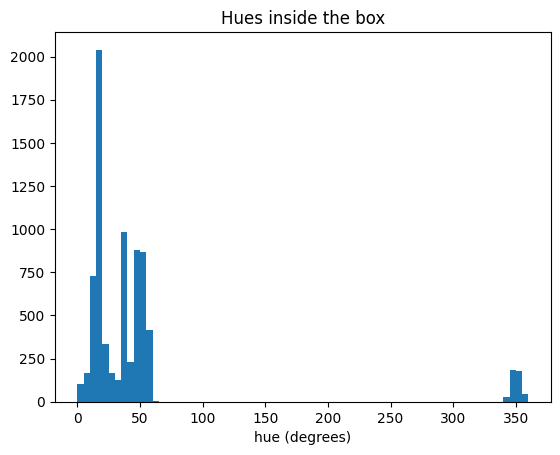

In [39]:
import numpy as np, matplotlib.pyplot as plt
box = [280, 385, 395, 450]
hsv = np.array(image.convert("HSV")).astype(float)
l, t, r, b = box
hue = hsv[t:b, l:r, 0] * 360 / 255
sat = hsv[t:b, l:r, 1]
plt.hist(hue[sat > 40].ravel(), bins=72, range=(0, 360))
plt.xlabel("hue (degrees)"); plt.title("Hues inside the box")
plt.show()

Selected pixels: 7475 | change outside selection: 0.0


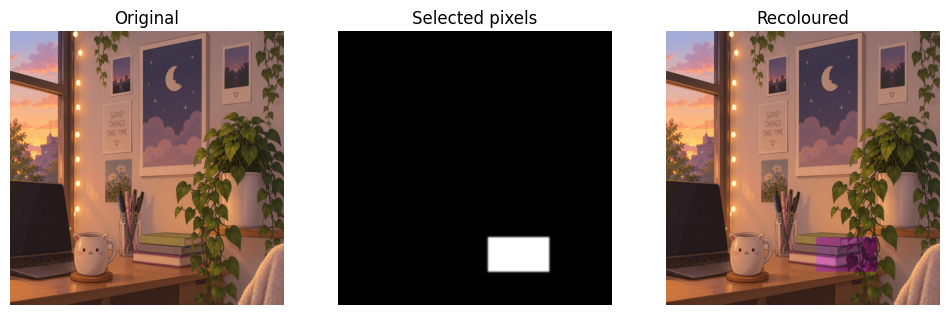

In [40]:
from PIL import Image, ImageFilter
import numpy as np, matplotlib.pyplot as plt

def recolour_hsv(name, base_img, box, hue_range, target_hue, sat_scale=1.0, min_sat=40):
    hsv = np.array(base_img.convert("HSV")).astype(float)
    h, s = hsv[..., 0], hsv[..., 1]
    hue_deg = h * 360 / 255

    in_box = np.zeros(h.shape, bool)
    l, t, r, b = box
    in_box[t:b, l:r] = True

    # only pixels inside the box that are coloured and in the chosen hue range
    sel = in_box & (s > min_sat) & (hue_deg >= hue_range[0]) & (hue_deg <= hue_range[1])
    sel_img = Image.fromarray((sel * 255).astype("uint8")).filter(ImageFilter.GaussianBlur(1.5))

    new = hsv.copy()
    new[..., 0] = np.where(sel, target_hue * 255 / 360, h)
    new[..., 1] = np.where(sel, np.clip(s * sat_scale, 0, 255), s)
    recoloured = Image.fromarray(new.astype("uint8"), "HSV").convert("RGB")

    final = Image.composite(recoloured, base_img, sel_img)
    final.save(f"/kaggle/working/outputs/{name}.png")

    outside = np.array(sel_img) == 0
    diff = np.abs(np.array(final).astype(float) - np.array(base_img).astype(float)).mean(axis=2)
    print("Selected pixels:", int(sel.sum()), "| change outside selection:", round(diff[outside].mean(), 3))

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, img, title in zip(axes, [base_img, sel_img, final], ["Original", "Selected pixels", "Recoloured"]):
        ax.imshow(img, cmap="gray" if title == "Selected pixels" else None)
        ax.set_title(title); ax.axis("off")
    plt.savefig(f"/kaggle/working/outputs/{name}_comparison.png", bbox_inches="tight")
    plt.show()

# edit hue_range to match the histogram; 320 is roughly pink, 270 lavender
recolour_hsv("books_hsv_pink", image, [280, 385, 395, 450], hue_range=(0, 360), target_hue=320)

### 15b: Hue shift inside the box

Pixels inside the box within a hue range have their hue shifted to pink (320 degrees) with brightness left alone, then the result is pasted back with a softened edge.

**Results**
- Selected pixels: 7475. Change outside the selection: 0.0
- 7475 is exactly the box area (115 by 65), and the "Selected pixels" panel is a solid white rectangle, so the whole box was tinted, not only the books
- The result is a pink patch over the desk, the books and part of the leaves

**What I noticed**
- The books are pale green and cream, which share hues with the leaves, the desk and the wall, so selecting by colour cannot separate the object from its surroundings
- The 0.0 is expected, as with the paste back, because pixels outside the selection are copied from the original

**Limits**
- One image, one hue range, one target colour

**Decision**
- Keep the hue shift, because it cannot change the shape, but select the object by outline instead of by colour
- Next (15c): Segment Anything (SAM), which turns a rough box into an object mask
- Keep this attempt as evidence of why selecting by colour was dropped

config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

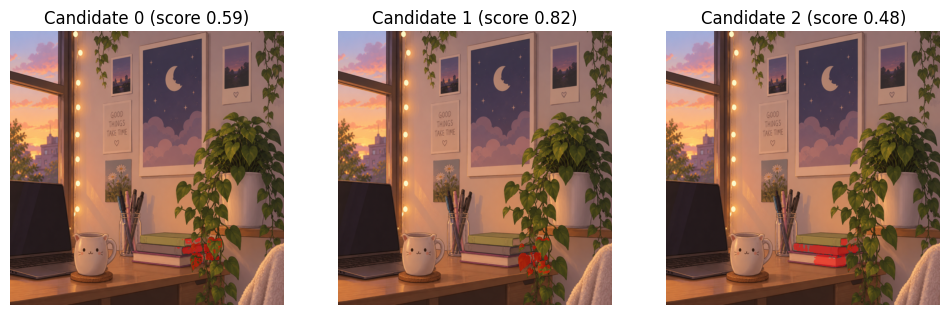

In [42]:
import torch, numpy as np, matplotlib.pyplot as plt
from PIL import Image
from transformers import SamModel, SamProcessor

sam = SamModel.from_pretrained("facebook/sam-vit-base").to(device)
sam_proc = SamProcessor.from_pretrained("facebook/sam-vit-base")

def sam_masks(img, box):
    inputs = sam_proc(img, input_boxes=[[list(box)]], return_tensors="pt").to(device)
    with torch.no_grad():
        out = sam(**inputs)
    masks = sam_proc.image_processor.post_process_masks(
        out.pred_masks.cpu(), inputs["original_sizes"].cpu(), inputs["reshaped_input_sizes"].cpu()
    )[0][0]                       # 3 candidate masks, shape (3, H, W)
    return masks.numpy(), out.iou_scores.cpu().numpy().ravel()

book_box = [280, 385, 395, 450]
cands, scores = sam_masks(image, book_box)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, ax in enumerate(axes):
    ov = np.array(image).copy()
    ov[cands[i]] = (0.5 * ov[cands[i]] + 0.5 * np.array([255, 0, 0])).astype("uint8")
    ax.imshow(ov); ax.set_title(f"Candidate {i} (score {scores[i]:.2f})"); ax.axis("off")
plt.show()

### 15c: SAM object mask plus hue shift

SAM is given the same box around the books and returns three candidate masks with a confidence score each. The chosen mask is recoloured with the same hue shift.

**Results**
- Candidate scores: 0.59, 0.82 and 0.48
- First run used candidate 0 (score 0.59): 1656 selected pixels in scattered blobs over the hanging flowers and leaves, not the books. Pink appeared on the plant and not on the book spines
- Candidate 1 (highest score, 0.82) only covered small areas
- Candidate 2 (lowest score, 0.48) looks like the full book stack in the preview
- [Add the result with candidate 2 or with point prompts: selected pixel count, and whether the books turned pink]

**What I noticed**
- The score is SAM's confidence in its own mask, not a check that it is the object I wanted. The highest score was not the right mask
- The box overlaps the leaves above the books, so SAM picks them up too
- [Note whether point prompts (a "yes" point on the books, "no" points on the leaves) fixed it]

**Limits**
- One image, one box, judged by eye

**Decisions**
- Choose the mask by looking at the candidates, not by score. In the prototype the user would pick from the candidates or correct with the brush
- Recolouring goes through an object mask plus a hue shift, not through a generative prompt
- Using SAM to turn a rough brush or box into an exact outline is [implemented / planned]: update after the next run

Selected pixels: 2850 | change outside selection: 0.0


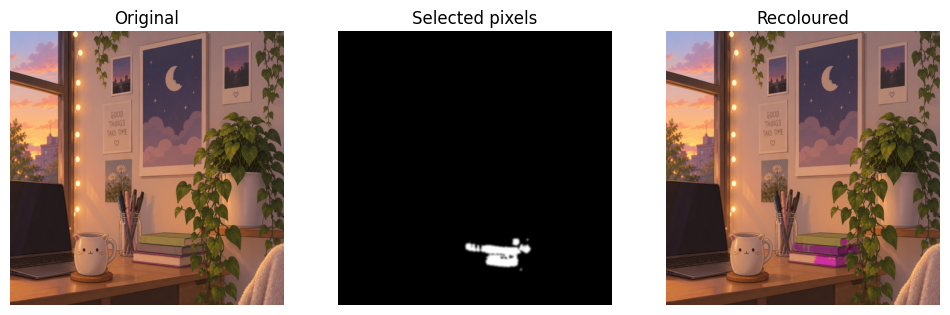

In [45]:
from PIL import ImageFilter

def recolour_mask(name, base_img, mask_bool, target_hue, sat_add=70):
    hsv = np.array(base_img.convert("HSV")).astype(float)
    sel_img = Image.fromarray((mask_bool * 255).astype("uint8")).filter(ImageFilter.GaussianBlur(1.5))

    new = hsv.copy()
    new[..., 0] = np.where(mask_bool, target_hue * 255 / 360, hsv[..., 0])      # new colour
    new[..., 1] = np.where(mask_bool, np.clip(hsv[..., 1] + sat_add, 0, 255), hsv[..., 1])  # pale pixels need more saturation
    # brightness (V) is untouched, so the shading and edges of the books survive
    recoloured = Image.fromarray(new.astype("uint8"), "HSV").convert("RGB")
    final = Image.composite(recoloured, base_img, sel_img)
    final.save(f"/kaggle/working/outputs/{name}.png")

    outside = np.array(sel_img) == 0
    diff = np.abs(np.array(final).astype(float) - np.array(base_img).astype(float)).mean(axis=2)
    print("Selected pixels:", int(mask_bool.sum()), "| change outside selection:", round(diff[outside].mean(), 3))

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, img, title in zip(axes, [base_img, sel_img, final], ["Original", "Selected pixels", "Recoloured"]):
        ax.imshow(img, cmap="gray" if title == "Selected pixels" else None); ax.set_title(title); ax.axis("off")
    plt.savefig(f"/kaggle/working/outputs/{name}_comparison.png", bbox_inches="tight")
    plt.show()

best = 2   # was 0
recolour_mask("books_15c_sam", image, cands[best], target_hue=320)

Selected pixels: 3953 | change outside selection: 0.0


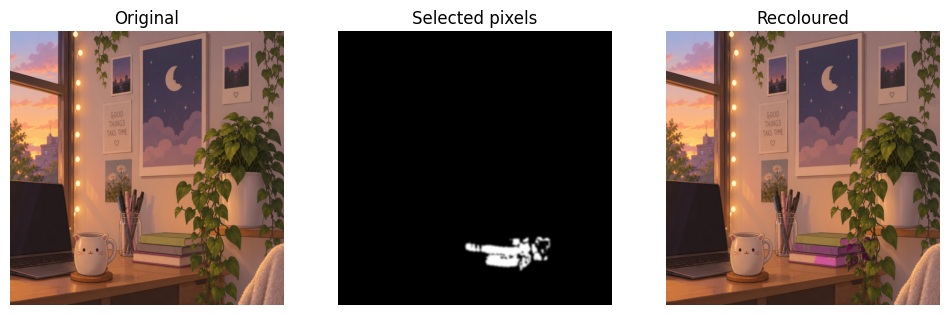

In [46]:
# books from candidate 2 plus the top book from another candidate, if one covers it
mask_all = cands[2] | cands[0]   # check the middle panel doesn't pick up leaves again
recolour_mask("books_15c_sam_soft", image, mask_all, target_hue=330, sat_add=25)

- Re-run with candidate 2 (score 0.48): 2850 selected pixels in a book-shaped strip, with nothing on the leaves. The lower books turned pink. Change outside the selection: 0.0
- The top green book was not selected, so the recolour is partial
- The colour came out as strong magenta, not the pastel pink and lavender I asked for. The hue shift keeps brightness, so it cannot make a book lighter or paler

- Candidate 1 had the highest score (0.82) but showed no visible mask in the preview. [or whatever you saw]
- Not tried yet: point prompts to include the top book. [update if you run it]


- Choose the mask by looking at the candidates, not the score. The prototype would let the user pick a candidate or correct it with the brush
- Recolour = object mask + hue shift, not a generative prompt. It keeps shape and shading and leaves everything outside the mask unchanged
- Limitation: hue shift cannot control paleness, so exact pastel colours are planned
- SAM-assisted masks: [implemented in the notebook / planned for the interface]. Pick one, depending on whether you wire it into Gradio

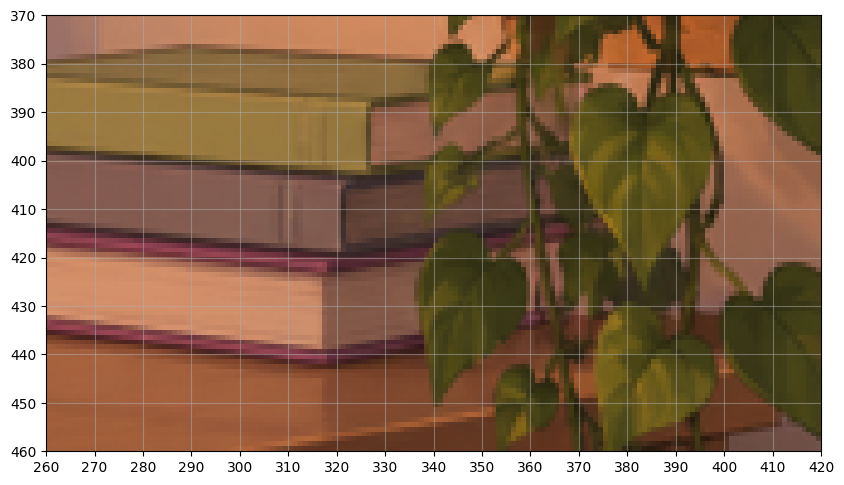

In [49]:
import matplotlib.pyplot as plt
x0, y0, x1, y1 = 260, 370, 420, 460
plt.figure(figsize=(10, 6))
plt.imshow(image.crop((x0, y0, x1, y1)), extent=(x0, x1, y1, y0))
plt.xticks(range(x0, x1 + 1, 10)); plt.yticks(range(y0, y1 + 1, 10))
plt.grid(alpha=0.5); plt.show()

In [55]:
def sam_masks_points(img, box, pos_pts, neg_pts):
    pts = pos_pts + neg_pts
    labels = [1] * len(pos_pts) + [0] * len(neg_pts)
    inputs = sam_proc(img, input_boxes=[[list(box)]], input_points=[pts],
                      input_labels=[labels], return_tensors="pt").to(device)
    with torch.no_grad():
        out = sam(**inputs)
    masks = sam_proc.image_processor.post_process_masks(
        out.pred_masks.cpu(), inputs["original_sizes"].cpu(), inputs["reshaped_input_sizes"].cpu()
    )[0][0]                       # 3 candidate masks, shape (3, H, W)
    return masks.numpy(), out.iou_scores.cpu().numpy().ravel()

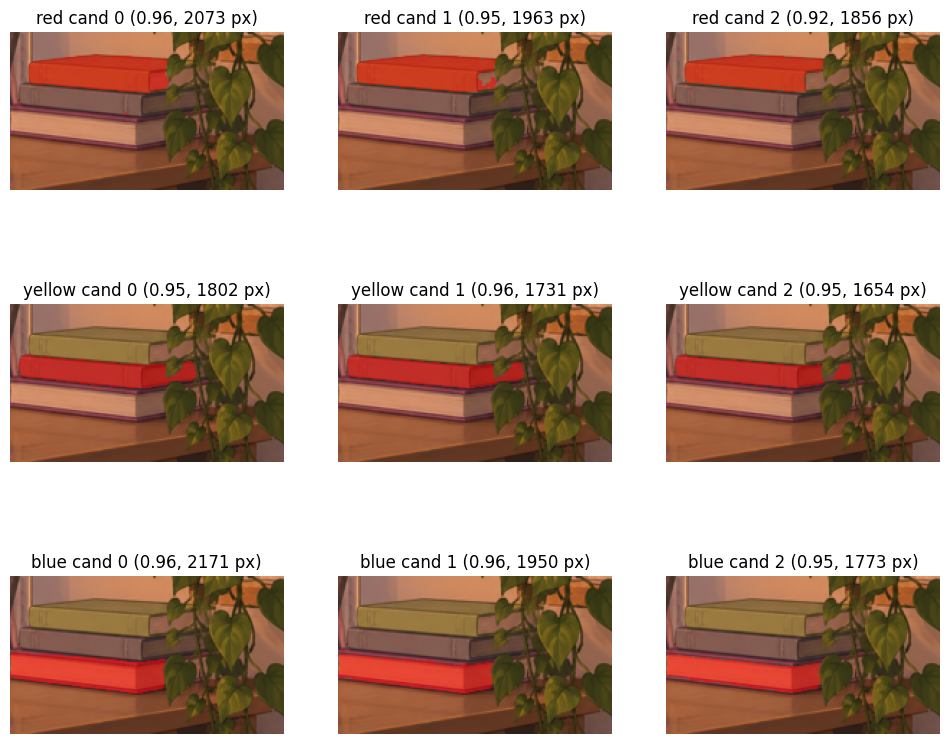

In [56]:
books = {
    "red":    dict(box=[240, 380, 345, 399], pos=[[300, 391]],
                   neg=[[352, 388], [375, 395]], hue=0),      # top green book
    "yellow": dict(box=[240, 399, 380, 416], pos=[[290, 407]],
                   neg=[[392, 410], [360, 395]], hue=50),     # middle grey-mauve book
    "blue":   dict(box=[240, 419, 380, 442], pos=[[285, 428], [300, 437]],
                   neg=[[392, 430], [370, 450]], hue=215),    # bottom cream book (pages and magenta edge)
}

all_cands = {}
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for r, (name, b) in enumerate(books.items()):
    c, s = sam_masks_points(image, b["box"], b["pos"], b["neg"])
    all_cands[name] = c
    for i in range(3):
        ov = np.array(image).copy()
        ov[c[i]] = (0.5 * ov[c[i]] + 0.5 * np.array([255, 0, 0])).astype("uint8")
        axes[r][i].imshow(ov[360:470, 230:420])
        axes[r][i].set_title(f"{name} cand {i} ({s[i]:.2f}, {int(c[i].sum())} px)")
        axes[r][i].axis("off")
plt.show()

In [67]:
def recolour_mask(name, base_img, mask_bool, target_hue, sat_add=70, v_scale=1.0):
    hsv = np.array(base_img.convert("HSV")).astype(float)
    sel_img = Image.fromarray((mask_bool * 255).astype("uint8")).filter(ImageFilter.GaussianBlur(1.5))

    new = hsv.copy()
    new[..., 0] = np.where(mask_bool, target_hue * 255 / 360, hsv[..., 0])
    new[..., 1] = np.where(mask_bool, np.clip(hsv[..., 1] + sat_add, 0, 255), hsv[..., 1])
    new[..., 2] = np.where(mask_bool, np.clip(hsv[..., 2] * v_scale, 0, 255), hsv[..., 2])   # new: brighten
    recoloured = Image.fromarray(new.astype("uint8"), "HSV").convert("RGB")

    final = Image.composite(recoloured, base_img, sel_img)
    final.save(f"/kaggle/working/outputs/{name}.png")
    outside = np.array(sel_img) == 0
    diff = np.abs(np.array(final).astype(float) - np.array(base_img).astype(float)).mean(axis=2)
    print(name, "| selected:", int(mask_bool.sum()), "| change outside:", round(diff[outside].mean(), 3))
    return final

In [69]:
print(type(books), list(books)[:3])

<class 'list'> [('red', [(260, 385), (385, 385), (385, 402), (260, 402)], 0.0), ('blue', [(260, 402), (385, 402), (385, 420), (260, 420)], 0.6), ('yellow', [(260, 420), (385, 420), (385, 437), (260, 437)], 0.14)]


books_15d_red | selected: 2073 | change outside: 0.0
books_15d_yellow | selected: 1802 | change outside: 0.0
books_15d_blue | selected: 2171 | change outside: 0.0


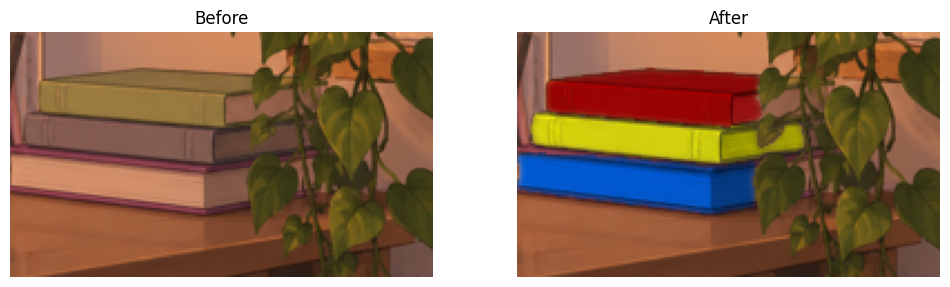

In [70]:
settings = {
    "red":    dict(sat_add=100, v_scale=1.0),
    "yellow": dict(sat_add=140, v_scale=1.6),
    "blue":   dict(sat_add=130, v_scale=1.0),
}
hues = {"red": 0, "yellow": 60, "blue": 215}

final = image.copy()
for name in ["red", "yellow", "blue"]:
    final = recolour_mask(f"books_15d_{name}", final, all_cands[name][0],
                          target_hue=hues[name], **settings[name])
final.save("/kaggle/working/outputs/books_15d_rgb_final.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, img, t in zip(axes, [image, final], ["Before", "After"]):
    ax.imshow(img.crop((230, 360, 420, 470))); ax.set_title(t); ax.axis("off")
plt.savefig("/kaggle/working/outputs/books_15d_comparison.png", bbox_inches="tight")
plt.show()

### 15d: One colour per book (SAM per book plus hue shift)

**What I did**
- Gave each book its own SAM mask using a tight box, a "yes" point on the book and "no" points on the leaves. Candidate 0 was chosen for all three (scores 0.95 to 0.96, 1802 to 2171 pixels each)
- Recoloured the books one after another with the hue shift: top book red, middle book yellow, bottom book blue
- Added saturation to each (100 for red, 140 for yellow, 130 for blue), because the grey-mauve and cream books have little colour to shift
- Pasted back with a softened edge. Change outside each selection: 0.0

**Results**
- All three books changed to the requested colour, and each mask covered only its own book. No colour spilled onto the leaves or the desk, and the shape, shading and spine details of each book were kept
- First run: the middle book came out dull olive, not yellow. The hue shift keeps the original brightness, and the grey-mauve book is dark, so a yellow hue on a dark pixel reads as olive
- Fix: changed the yellow hue to 60 degrees and added a brightness boost (v_scale 1.6). The middle book now reads as yellow
- The bottom book's mask also covered its cream pages, so the pages turned blue along with the cover

**What I noticed**
- Selecting by object outline worked where prompting (15a) and selecting by colour (15b) did not. Those two failures led to this design
- SAM selects an object, not a part of it. It cannot tell the cover from the pages, so the mask followed the whole block
- Hue alone is not enough for light colours, because brightness has to change too. This needed a per-book setting chosen by eye

**Limits**
- One image, one box per book and one set of settings, judged by eye
- Points for the masks were placed by hand from a pixel grid, so this is assisted selection, not automatic

**Decisions**
- Recolouring uses an object mask plus a hue shift, not a generative prompt
- The prototype shows the candidate masks and lets the user pick one, with a brush to correct it, because a mask can cover too much (the pages)
- Next (15e): put the pages back to their original colour
- Pastel colours are planned

Change outside the box: 0.0


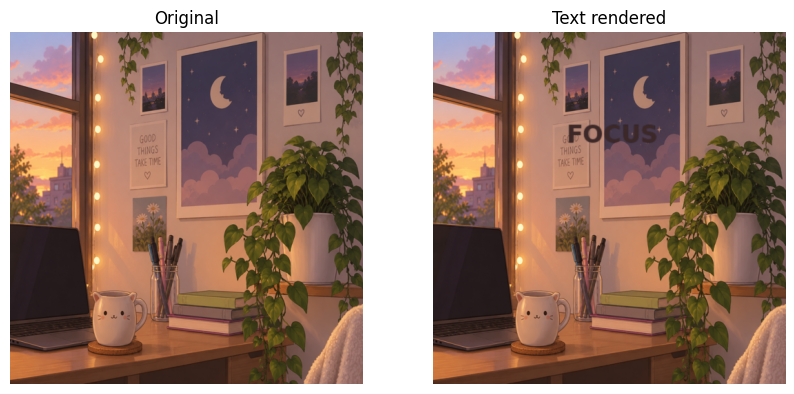

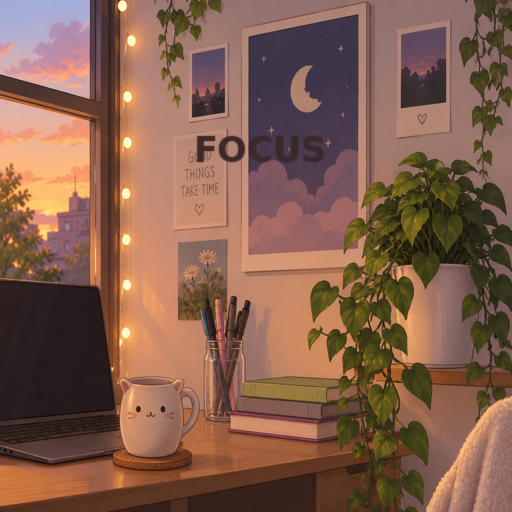

In [41]:
from PIL import Image, ImageDraw, ImageFont, ImageFilter
import matplotlib.pyplot as plt, matplotlib.font_manager as fm, numpy as np

def add_text(name, base_img, box, text, colour=(60, 40, 40), clean_first=False, blur=0.6):
    work = base_img.copy()
    mask = Image.new("L", (512, 512), 0)
    ImageDraw.Draw(mask).rectangle(box, fill=255)

    if clean_first:   # wipe garbled text with LaMa first
        cleaned = lama(work, mask.filter(ImageFilter.MaxFilter(13))).convert("RGB").resize((512, 512))
        work = Image.composite(cleaned, work, mask.filter(ImageFilter.GaussianBlur(4)))

    l, t, r, b = box
    font_path = fm.findfont("DejaVu Sans:bold")
    size = 10
    while True:   # grow the font until the word fills ~85% of the box width
        font = ImageFont.truetype(font_path, size + 1)
        w = ImageDraw.Draw(work).textlength(text, font=font)
        if w > (r - l) * 0.85 or size > 200:
            break
        size += 1
    font = ImageFont.truetype(font_path, size)

    layer = Image.new("RGBA", work.size, (0, 0, 0, 0))
    d = ImageDraw.Draw(layer)
    tw = d.textlength(text, font=font)
    d.text(((l + r - tw) / 2, (t + b) / 2 - size * 0.6), text, font=font, fill=colour + (255,))
    layer = layer.filter(ImageFilter.GaussianBlur(blur))   # softens edges to match the illustration

    final = Image.alpha_composite(work.convert("RGBA"), layer).convert("RGB")
    # keep everything outside the box identical
    final = Image.composite(final, base_img, mask.filter(ImageFilter.GaussianBlur(3)))
    final.save(f"/kaggle/working/outputs/{name}.png")

    outside = np.array(mask.filter(ImageFilter.GaussianBlur(3))) == 0
    diff = np.abs(np.array(final).astype(float) - np.array(base_img).astype(float)).mean(axis=2)
    print("Change outside the box:", round(diff[outside].mean(), 3))

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    for ax, img, title in zip(axes, [base_img, final], ["Original", "Text rendered"]):
        ax.imshow(img); ax.set_title(title); ax.axis("off")
    plt.savefig(f"/kaggle/working/outputs/{name}_comparison.png", bbox_inches="tight")
    plt.show()
    return final

add_text("poster_focus_font", image, [180, 100, 340, 200], "FOCUS")

Change outside the box: 0.0


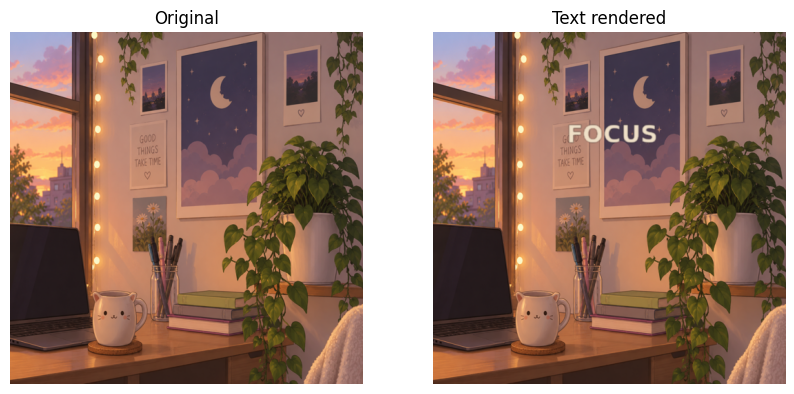

  0%|          | 0/7 [00:00<?, ?it/s]

strength 0.25, seed 1: change outside = 0.0


  0%|          | 0/7 [00:00<?, ?it/s]

strength 0.25, seed 7: change outside = 0.0


  0%|          | 0/12 [00:00<?, ?it/s]

strength 0.4, seed 1: change outside = 0.0


  0%|          | 0/12 [00:00<?, ?it/s]

strength 0.4, seed 7: change outside = 0.0


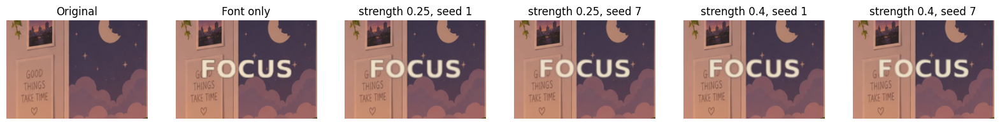

In [77]:
# step 1: exact spelling from the font, in a cream colour
drawn = add_text("poster_focus_step1", image, [180, 100, 340, 200], "FOCUS",
                 colour=(240, 225, 200), blur=0.8)

# mask = only the pixels the text changed, grown a little
diff = np.abs(np.array(drawn).astype(int) - np.array(image).astype(int)).sum(axis=2)
text_mask = Image.fromarray(((diff > 30) * 255).astype("uint8")).filter(ImageFilter.MaxFilter(9))
soft = text_mask.filter(ImageFilter.GaussianBlur(3))

base_big, mask_big = drawn.resize((1024, 1024)), text_mask.resize((1024, 1024))
prompt = "the word FOCUS printed on a poster, soft flat cartoon illustration, matching the style of the scene, painted shading"
negative = "3d render, glossy, photorealistic, blurry, watermark, extra letters"

l, t, r, b = 180, 100, 340, 200
crop = (l - 20, t - 20, r + 20, b + 20)
runs = [(0.25, 1), (0.25, 7), (0.4, 1), (0.4, 7)]      # (strength, seed)

fig, axes = plt.subplots(1, len(runs) + 2, figsize=(20, 4))
axes[0].imshow(image.crop(crop)); axes[0].set_title("Original")
axes[1].imshow(drawn.crop(crop)); axes[1].set_title("Font only")

for i, (strength, seed) in enumerate(runs):
    out = pipe_xl(prompt=prompt, negative_prompt=negative, image=base_big, mask_image=mask_big,
                  padding_mask_crop=64, guidance_scale=5.5, strength=strength, num_inference_steps=30,
                  generator=torch.Generator(device).manual_seed(seed)).images[0]
    pasted = Image.composite(out.resize((512, 512)), image, soft)
    pasted.save(f"/kaggle/working/outputs/poster_focus_blend_s{strength}_seed{seed}.png")
    axes[i + 2].imshow(pasted.crop(crop)); axes[i + 2].set_title(f"strength {strength}, seed {seed}")

    outside = np.array(soft) == 0
    d = np.abs(np.array(pasted).astype(float) - np.array(image).astype(float)).mean(axis=2)
    print(f"strength {strength}, seed {seed}: change outside =", round(d[outside].mean(), 3))

for ax in axes: ax.axis("off")
plt.savefig("/kaggle/working/outputs/poster_focus_blend_comparison.png", bbox_inches="tight")
plt.show()

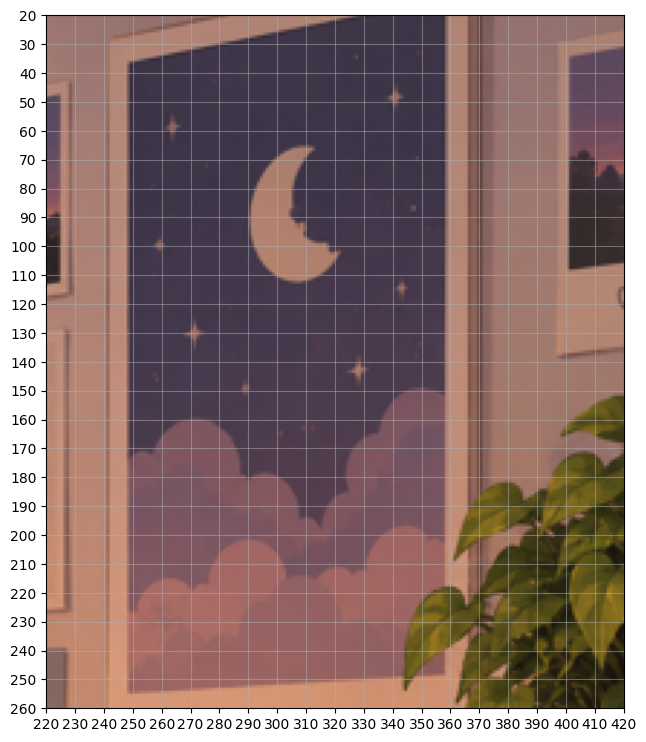

In [100]:
plt.figure(figsize=(9, 9))
plt.imshow(image.crop((220, 20, 420, 260)), extent=(220, 420, 260, 20))
plt.xticks(range(220, 421, 10)); plt.yticks(range(20, 261, 10))
plt.grid(alpha=0.5); plt.show()

In [101]:
import math

# two points on the SAME straight edge of the poster frame (x, y), read from the grid
p1, p2 = (232, 42), (395, 38)        # placeholders: replace with your readings

dx, dy = p2[0] - p1[0], p2[1] - p1[1]
angle = -math.degrees(math.atan2(dy, dx))     # PIL rotates counterclockwise, image y points down
print("Tilt to use:", round(angle, 1), "degrees")

Tilt to use: 1.4 degrees


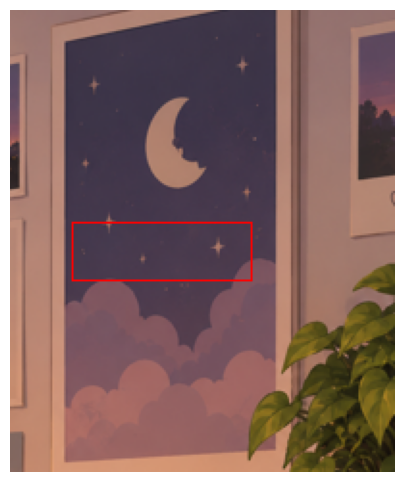

In [102]:
box = [252, 130, 345, 160]      # replace with your readings: left, top, right, bottom, all inside the purple

preview = image.copy()
ImageDraw.Draw(preview).rectangle(box, outline=(255, 0, 0), width=1)
plt.figure(figsize=(6, 6)); plt.imshow(preview.crop((220, 20, 420, 260))); plt.axis("off"); plt.show()

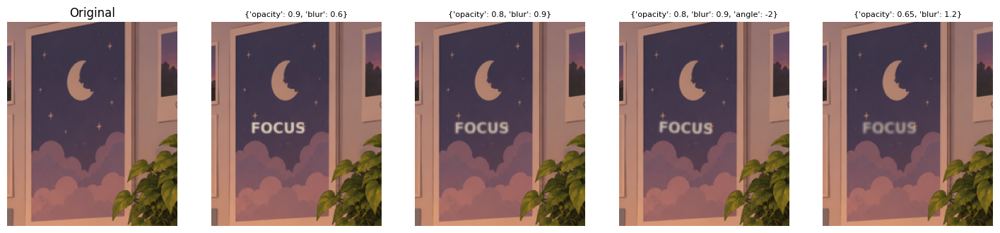

In [103]:
variants = [dict(opacity=0.9, blur=0.6), dict(opacity=0.8, blur=0.9),
            dict(opacity=0.8, blur=0.9, angle=-2), dict(opacity=0.65, blur=1.2)]

crop = (220, 20, 420, 260)
fig, axes = plt.subplots(1, len(variants) + 1, figsize=(18, 5))
axes[0].imshow(image.crop(crop)); axes[0].set_title("Original")
for i, v in enumerate(variants):
    out = ink_text(f"poster_focus_moon_{i}", image, box, "FOCUS",
                   ink=(235, 220, 195), grain=3, size_frac=0.7, clean_first=False, **v)
    axes[i + 1].imshow(out.crop(crop)); axes[i + 1].set_title(str(v), fontsize=8)
for ax in axes: ax.axis("off")
plt.savefig("/kaggle/working/outputs/poster_focus_moon_comparison.png", bbox_inches="tight")
plt.show()

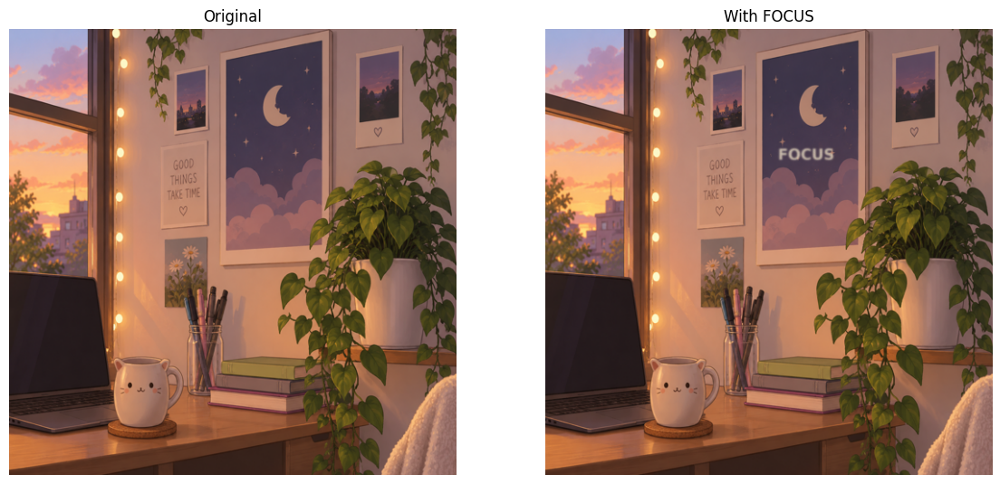

Change outside the box: 0.0


In [105]:
best = dict(opacity=0.8, blur=0.9, angle=0)

result = ink_text("poster_focus_moon_final", image, box, "FOCUS",
                  ink=(235, 220, 195), grain=3, size_frac=0.7, clean_first=False, **best)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, img, t in zip(axes, [image, result], ["Original", "With FOCUS"]):
    ax.imshow(img); ax.set_title(t); ax.axis("off")
plt.savefig("/kaggle/working/outputs/poster_focus_moon_full.png", bbox_inches="tight")
plt.show()

# change outside the box (a 4 pixel margin is left out for the soft edge)
d = np.abs(np.array(result).astype(float) - np.array(image).astype(float)).mean(axis=2)
m = np.ones(d.shape, bool)
m[box[1]-4:box[3]+4, box[0]-4:box[2]+4] = False
print("Change outside the box:", round(d[m].mean(), 3))

## Text edit: printed text on the moon poster

The first text test (Stable Diffusion 1.5) repeated the word and misspelled both copies. This section tries to get exact spelling and make it look part of the scene. Each step changed one thing.

### What I did
- **Font render:** drew "FOCUS" with a bold font in a box on the moon poster. The first colour was dark brown, which had almost no contrast on the navy poster, so I changed it to cream to match printed text
- **Font plus SDXL pass:** made a mask from only the pixels the text changed and ran SDXL inpainting over it (strength 0.25 and 0.4, seeds 1 and 7, guidance 5.5, padding_mask_crop 64), pasted back with a softened edge
- **Printed-ink version:** drew the text at 4 times the size and shrunk it for smooth edges, set the opacity to 0.65 to 0.9, blurred it slightly and added a little grain so the poster shows through the letters. Tried four settings and chose the best by eye
- **Placement:** checked the box by drawing it in red on the image before rendering, and read the poster's edges off a pixel grid. The final box is [252, 130, 345, 160], entirely on the purple part of the poster, below the moon

### Results
- Spelling was correct in every font-based version, including after the SDXL pass at strength 0.4. The SDXL-only version from the first test never spelled it correctly
- The SDXL pass at low strength changed the letters very little, so the result still looked like the font layer
- Final version (opacity [0.8], blur [0.9]): [looks part of the poster / still looks slightly added on]. [Describe at normal size, not zoomed in]
- Change outside the box: [0.0 or the number printed]. This is expected, because pixels outside the box are copied from the original

### What I noticed
- My first boxes landed in the wrong places: on the white wall, then on the small white poster, then on the frame of the moon poster. I only found this by drawing the box on the image. Placement mattered more than the blending
- Splitting the job worked better than one model doing everything: the font gives the letters, and opacity, blur and grain make them sit in the scene
- A flat, sharp, fully opaque word looks added on until its colour, softness and opacity match the surface it is on
- The poster is slightly tilted in the picture, and the level text does not follow it. I did not correct for this

### Limits
- One image, one word, one font and one poster, judged by eye
- The text uses a fixed font, so it will not match hand-drawn lettering
- The box position was chosen by hand from a pixel grid

### Decisions
- Text edits go through a font renderer, not a prompt to the model
- Showing the box on the image before applying, so the user can check where the edit will land, is part of the interface (preview)
- Keep the garbled SDXL text from the first test as an "AI gets it wrong" example
- Planned: a layout-guided model (for example ControlNet) for text that follows the surface's tilt and style, and matching the poster's perspective
- Text routing is [implemented in the notebook / planned for the interface]

# Summary: inpainting experiments

## Aim
Test whether editing a selected region can change one detail of an image while leaving the rest untouched, and find out which edits each model does well.

## Models and tools
- **Stable Diffusion 1.5 inpainting:** first model, run on a Kaggle T4 GPU
- **LaMa (simple-lama-inpainting):** object removal
- **SDXL inpainting:** adding or replacing an object, with better style and prompt following
- **Segment Anything (SAM):** object masks for the recolour tests
- **Font renderer (PIL):** exact text
- **Method for every edit:** mask the area, edit, paste back with a softened edge, measure the change outside the mask

## Key result: leakage and paste back
| Test | Raw model change outside the mask (0 to 255 scale) | After paste back |
|---|---|---|
| Poster text | 6.086 | 0.0 |
| Mug recolour | 5.451 | 0.0 |
| Add object (v2) | 5.214 | 0.0 |
| Remove mug, four seeds | 5.269 to 5.612 | 0.0 |

- The model redraws the whole image internally, so areas outside the mask shift by about 2% of the scale. For example, the frame on the left wall and the pen pot changed even though they were not selected
- Pasting the edited area back onto the original removes this
- Runs that use padding_mask_crop print 0.0 for the raw change, because the crop is pasted back by the library, so those runs cannot show leakage
- Limit: one image, a few masks, mostly one seed (42)

## What worked
- **Removal:** LaMa removed the mug and coaster once the mask had a margin. A tight mask left a pale ghost of the mug
- **Add or replace an object:** SDXL replaced the mug with a succulent in a white pot in one step on the original image, in all four seeds
- **Text:** a font renderer gave correct spelling every time. Cream colour, partial transparency, blur and grain made the word sit on the poster better than the plain font render

## What went wrong
- **Poster text with SD 1.5:** repeated the word and misspelled both copies
- **Recolouring the mug:** the model replaced the whole object, and none of the strengths (1.0, 0.75, 0.5) kept the original or made it blue
- **Removing the mug with SD 1.5:** every attempt invented something (plants, bowls, cups, a blob)
- **Recolouring the books by prompt (SDXL):** the colours did not change
- **Safety checker:** blacked out harmless images, so it was switched off for this scene
- **Style:** SDXL objects looked glossier than the flat illustrated scene, so style matching is only partly solved

## Recolouring: tried and dropped
- Prompting SDXL for a new colour failed twice (mug and books)
- Selecting pixels by hue tinted the whole box, because the books share hues with the leaves and desk
- Object masks from SAM plus a hue shift recoloured each book separately (red, yellow, blue) with no change outside the selection. The masks followed whole books, so the pages changed colour too, and the mask edges were jagged
- Restoring the pages by colour threshold only recovered small patches
- Decision: dropped recolouring, because it did not support the main interaction. The lesson kept is that a mask can cover too much of an object, so a mask needs a preview and a way to correct it

## Decisions drawn from these tests
1. **Paste back is a fixed step** in every edit, so only the selected area can change
2. **Route by intent:** removal goes to LaMa, text goes to the font renderer, and add or change goes to SDXL
3. **Use padding_mask_crop** and a mask with a margin for removal
4. **Offer several seeds as options,** with preview and undo, because results vary a lot with the seed and the model is sometimes wrong
5. **Show the mask on the image before applying it,** because several of my own boxes landed in the wrong place
6. **Not built:** style matching inside the edit, recolouring, part-level selection (cover versus pages), and a layout-guided model for text that follows the surface

## Limits of these results
- One image, mostly one seed and a few masks per edit
- Quality was judged by eye with no scoring. The leakage measure is the only measured result

  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

Whole image regenerated: change outside the mug area = 18.478
Local edit + paste back: change outside the mug area = 0.000


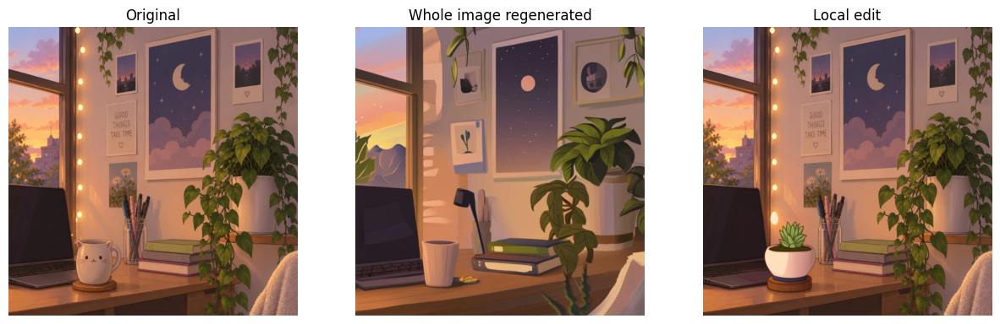

In [106]:
import numpy as np, matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter

box = [60, 330, 195, 465]          # the area I care about (mug)
seed = 7
plant = "a small succulent in a cute round white pot on a wooden desk, soft flat cartoon illustration"

# --- Way 1: regenerate the whole image (mask = everything) ---
full_mask = Image.new("L", (512, 512), 255)
out1 = pipe_xl(
    prompt="a cosy study space with a desk, laptop, books, " + plant + ", warm sunset lighting",
    negative_prompt="3d render, glossy, photorealistic, blurry, text, watermark",
    image=image.resize((1024, 1024)), mask_image=full_mask.resize((1024, 1024)),
    guidance_scale=5.5, strength=0.6, num_inference_steps=30,
    generator=torch.Generator(device).manual_seed(seed),
).images[0].resize((512, 512))

# --- Way 2: local edit with paste back ---
mask = Image.new("L", (512, 512), 0)
ImageDraw.Draw(mask).rectangle(box, fill=255)
soft = mask.filter(ImageFilter.GaussianBlur(5))
out2 = pipe_xl(
    prompt=plant, negative_prompt="3d render, glossy, photorealistic, blurry, text, watermark, mug, cup",
    image=image.resize((1024, 1024)), mask_image=mask.resize((1024, 1024)),
    padding_mask_crop=64, guidance_scale=5.5, num_inference_steps=30,
    generator=torch.Generator(device).manual_seed(seed),
).images[0].resize((512, 512))
out2 = Image.composite(out2, image, soft)

# --- measure: average change outside the mug box (0 to 255 scale) ---
outside = np.array(soft) == 0
orig = np.array(image).astype(float)
for name, img in [("Whole image regenerated", out1), ("Local edit + paste back", out2)]:
    d = np.abs(np.array(img).astype(float) - orig).mean(axis=2)
    print(f"{name}: change outside the mug area = {d[outside].mean():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, t in zip(axes, [image, out1, out2], ["Original", "Whole image regenerated", "Local edit"]):
    ax.imshow(img); ax.set_title(t); ax.axis("off")
plt.savefig("/kaggle/working/outputs/regenerate_vs_local.png", bbox_inches="tight")
plt.show()

## Local edit versus regenerating the whole image

My literature review asked whether editing a selected region keeps the rest of an image intact better than regenerating from a changed prompt. This test uses the same change (mug to succulent), the same seed (7) and the same model (SDXL inpainting), done two ways.

**What I did**
- **Whole image regenerated:** mask covering the whole image, a prompt describing the scene plus the succulent, strength 0.6
- **Local edit:** mask around the mug only, with paste back, as in the prototype
- Measured the average change per pixel outside the mug area (0 to 255 scale)

**Results**
- Whole image regenerated: 18.478 (about 7% of the scale)
- Local edit with paste back: 0.000
- The regenerated image looks like a different room: the window, posters, plants and layout changed, a lamp appeared, and the desk shows a white mug and no succulent
- The local edit kept the room as it was and replaced only the mug with a succulent in a white pot

**What I noticed**
- Regenerating to change one detail altered parts that were already right, which is the problem described in my literature review
- It also failed to deliver the change that was asked for, so a user would have to keep adjusting the prompt and regenerating
- Raw inpainting output without paste back changed 5 to 6 on the same scale (6.086, 5.451, 5.214), so regenerating everything is clearly worse than inpainting, and paste back is the step that gets it to 0

**Limits**
- One image, one seed, one strength (0.6) and one prompt, so this is an example and not a general finding. A lower strength would change less
- The local result is 0.000 because paste back copies the outside pixels from the original. The useful number is 18.478
- Only the area outside the mug was measured. I did not score whether the new plant looks good, which was judged by eye

**Decision**
- Every edit in the prototype uses a mask and paste back, so the rest of the image stays unchanged
- Keep this comparison as the main evidence for the design, and use the saved image in the report